In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast
from pandas import json_normalize
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import TargetEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_regression
from sklearn.feature_selection import RFECV
from sklearn.model_selection import cross_validate, KFold, cross_val_predict
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)

In [30]:
bangalore = pd.read_excel("C:/Users/sathv/Desktop/Regression@Beamx/bangalore_cars.xlsx", engine="openpyxl")
chennai = pd.read_excel("C:/Users/sathv/Desktop/Regression@Beamx/chennai_cars.xlsx", engine="openpyxl")
delhi = pd.read_excel("C:/Users/sathv/Desktop/Regression@Beamx/delhi_cars.xlsx", engine="openpyxl")
hyderabad = pd.read_excel("C:/Users/sathv/Desktop/Regression@Beamx/hyderabad_cars.xlsx", engine="openpyxl")
jaipur = pd.read_excel("C:/Users/sathv/Desktop/Regression@Beamx/jaipur_cars.xlsx", engine="openpyxl")
kolkata = pd.read_excel("C:/Users/sathv/Desktop/Regression@Beamx/kolkata_cars.xlsx", engine="openpyxl")

## Bangalore

In [31]:
bangalore.head()

,new_car_detail,new_car_overview,new_car_feature,new_car_specs,car_links
0,"{'it': 0, 'ft': 'Petrol', 'bt': 'Hatchback', '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/used-car-details/used...
1,"{'it': 0, 'ft': 'Petrol', 'bt': 'SUV', 'km': '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/buy-used-car-details/...
2,"{'it': 0, 'ft': 'Petrol', 'bt': 'Hatchback', '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/used-car-details/used...
3,"{'it': 0, 'ft': 'Petrol', 'bt': 'Sedan', 'km':...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/buy-used-car-details/...
4,"{'it': 0, 'ft': 'Diesel', 'bt': 'SUV', 'km': '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/used-car-details/used...


In [32]:
bangalore.shape

(1481, 5)

In [33]:
#extracting the new_car_detail
bangalore["new_car_detail"] = bangalore["new_car_detail"].apply(ast.literal_eval)
detailed_bangalore = json_normalize(bangalore["new_car_detail"])

In [34]:
detailed_bangalore.shape

(1481, 19)

In [35]:
detailed_bangalore.head(2)

,it,ft,bt,km,transmission,ownerNo,owner,oem,model,modelYear,centralVariantId,variantName,price,priceActual,priceSaving,priceFixedText,trendingText.imgUrl,trendingText.heading,trendingText.desc
0,0,Petrol,Hatchback,"1,20,000",Manual,3,3rd Owner,Maruti,Maruti Celerio,2015,3979,VXI,₹ 4 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days
1,0,Petrol,SUV,"32,706",Manual,2,2nd Owner,Ford,Ford Ecosport,2018,6087,1.5 Petrol Titanium BSIV,₹ 8.11 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days


In [36]:
#extracting the new_car_overview
overview = ast.literal_eval(bangalore.loc[0, "new_car_overview"])
print(type(overview))
print(overview.keys())

<class 'dict'>
dict_keys(['heading', 'top', 'bottomData'])


In [37]:
print(type(overview["heading"]))
print(overview["heading"])

<class 'str'>
Car overview


In [38]:
print(type(overview["top"]))
print(overview["top"])

<class 'list'>
[{'key': 'Registration Year', 'value': '2015', 'icon': 'https://images10.gaadi.com/listing/vdp/co/v1/registrationYear.svg'}, {'key': 'Insurance Validity', 'value': 'Third Party insurance', 'icon': 'https://images10.gaadi.com/listing/vdp/co/v1/insuranceValidity.svg'}, {'key': 'Fuel Type', 'value': 'Petrol', 'icon': 'https://images10.gaadi.com/listing/vdp/co/v1/fuel.svg'}, {'key': 'Seats', 'value': '5 Seats', 'icon': 'https://images10.gaadi.com/listing/vdp/co/v1/seats.svg'}, {'key': 'Kms Driven', 'value': '1,20,000 Kms', 'icon': 'https://images10.gaadi.com/listing/vdp/co/v1/kmsDriven.svg'}, {'key': 'RTO', 'value': 'KA51', 'icon': 'https://images10.gaadi.com/listing/vdp/co/v1/rto.svg'}, {'key': 'Ownership', 'value': 'Third Owner', 'icon': 'https://images10.gaadi.com/listing/vdp/co/v1/ownership.svg'}, {'key': 'Engine Displacement', 'value': '998 cc', 'icon': 'https://images10.gaadi.com/listing/vdp/co/v1/engineDisplacement.svg'}, {'key': 'Transmission', 'value': 'Manual', 'ic

In [39]:
print(type(overview["bottomData"]))
print(overview["bottomData"])

<class 'NoneType'>
None


In [40]:
def extract_overview(data):
    if isinstance(data, str):
        data = ast.literal_eval(data)
    result = {}
    for item in data["top"]:
        key = item["key"]
        if key == "Seats":
            key = "overview_Seats"
        result[key] = item["value"]
    return result

In [41]:
overview_bangalore = pd.DataFrame(bangalore["new_car_overview"].apply(extract_overview).tolist())

In [42]:
overview_bangalore.shape

(1481, 10)

In [43]:
overview_bangalore.head()

,Registration Year,Insurance Validity,Fuel Type,overview_Seats,Kms Driven,RTO,Ownership,Engine Displacement,Transmission,Year of Manufacture
0,2015,Third Party insurance,Petrol,5 Seats,"1,20,000 Kms",KA51,Third Owner,998 cc,Manual,2015.0
1,Feb 2018,Comprehensive,Petrol,5 Seats,"32,706 Kms",KA05,Second Owner,1497 cc,Manual,2018.0
2,Sept 2018,Comprehensive,Petrol,5 Seats,"11,949 Kms",KA03,First Owner,1199 cc,Manual,2018.0
3,Dec 2014,Comprehensive,Petrol,5 Seats,"17,794 Kms",KA53,First Owner,1197 cc,Manual,2014.0
4,2015,Third Party insurance,Diesel,5 Seats,"60,000 Kms",KA04,First Owner,1248 cc,Manual,2015.0


In [44]:
#extracting the new_car_features
feature = ast.literal_eval(bangalore.loc[0, "new_car_feature"])
print(feature.keys())
print(type(feature["heading"]))
print(feature["heading"])

dict_keys(['heading', 'top', 'data', 'commonIcon'])
<class 'str'>
Features


In [45]:
print(type(feature["top"]))
print(feature["top"])

<class 'list'>
[{'value': 'Power Steering'}, {'value': 'Power Windows Front'}, {'value': 'Air Conditioner'}, {'value': 'Heater'}, {'value': 'Adjustable Head Lights'}, {'value': 'Manually Adjustable Exterior Rear View Mirror'}, {'value': 'Centeral Locking'}, {'value': 'Child Safety Locks'}]


In [46]:
print(type(feature["data"]))
print(feature["data"])

<class 'list'>
[{'heading': 'Comfort & Convenience', 'subHeading': 'Comfort', 'list': [{'value': 'Power Steering'}, {'value': 'Power Windows Front'}, {'value': 'Power Windows Rear'}, {'value': 'Remote Trunk Opener'}, {'value': 'Remote Fuel Lid Opener'}, {'value': 'Low Fuel Warning Light'}, {'value': 'Accessory Power Outlet'}, {'value': 'Vanity Mirror'}, {'value': 'Rear Seat Headrest'}, {'value': 'Cup Holders Front'}]}, {'heading': 'Interior', 'subHeading': 'Interior', 'list': [{'value': 'Air Conditioner'}, {'value': 'Heater'}, {'value': 'Digital Odometer'}, {'value': 'Electronic Multi Tripmeter'}, {'value': 'Fabric Upholstery'}, {'value': 'Glove Compartment'}, {'value': 'Digital Clock'}]}, {'heading': 'Exterior', 'subHeading': 'Exterior', 'list': [{'value': 'Adjustable Head Lights'}, {'value': 'Manually Adjustable Exterior Rear View Mirror'}, {'value': 'Wheel Covers'}, {'value': 'Power Antenna'}, {'value': 'Chrome Grille'}]}, {'heading': 'Safety', 'subHeading': 'Safety', 'list': [{'val

In [47]:
print(type(feature["commonIcon"]))
print(feature["commonIcon"])

<class 'str'>
https://stimg.cardekho.com/pwa/img/vdpN/tickG.svg


In [48]:
def extract_feature_column(df, column_name):
    rows = []
    for value in df[column_name]:
        if isinstance(value, str):
            value = ast.literal_eval(value)
        row = {}
        for section in value["data"]:
            for item in section["list"]:
                row[item["value"]] = 1
        rows.append(row)
    return pd.DataFrame(rows).fillna(0)

In [49]:
features_bangalore = extract_feature_column(bangalore, "new_car_feature")

In [50]:
features_bangalore.shape

(1481, 173)

In [51]:
features_bangalore.head()

,Power Steering,Power Windows Front,Power Windows Rear,Remote Trunk Opener,Remote Fuel Lid Opener,Low Fuel Warning Light,Accessory Power Outlet,Vanity Mirror,Rear Seat Headrest,Cup Holders Front,...,Cassette Player,Find My Car Location,Wifi Connectivity,Headlamp Washers,Real Time Vehicle Tracking,Roof Carrier,Smart Key Band,Lane Watch Camera,Removable Convertible Top,Power Folding3rd Row Seat
0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [52]:
# extraction for new_car_Specs
specs = ast.literal_eval(bangalore.loc[0, "new_car_specs"])
print(specs.keys())
print(specs["top"][0])

dict_keys(['heading', 'top', 'data', 'commonIcon'])
{'key': 'Mileage', 'value': '23.1 kmpl'}


In [53]:
def extract_specs(df, column_name):
    rows = []
    for value in df[column_name]:
        if isinstance(value, str):
            value = ast.literal_eval(value)
        row = {}
        # Extract from top
        for item in value["top"]:
            row[item["key"]] = item["value"]
        # Extract from data
        for section in value["data"]:
            for item in section["list"]:
                row[item["key"]] = item["value"]
        rows.append(row)
    return pd.DataFrame(rows)

In [54]:
specs_bangalore = extract_specs(bangalore, "new_car_specs")

In [55]:
specs_bangalore.shape

(1481, 40)

In [56]:
specs_bangalore.head(2)

,Mileage,Engine,Max Power,Torque,Seats,Color,Engine Type,Displacement,Max Torque,No of Cylinder,...,Front Brake Type,Rear Brake Type,Top Speed,Acceleration,Tyre Type,No Door Numbers,Cargo Volumn,Wheel Size,Alloy Wheel Size,Ground Clearance Unladen
0,23.1 kmpl,998 CC,67.04bhp@6000rpm,90Nm,5,White,K10B Engine,998,90Nm@3500rpm,3.0,...,Ventilated Disc,Drum,150 Kmph,15.05 Seconds,"Tubeless, Radial",5,235-litres,NaN,NaN,NaN
1,17 kmpl,1497 CC,121.31bhp@6500rpm,150Nm,5,White,Ti-VCT Petrol Engine,1497,150Nm@4500rpm,3.0,...,Ventilated Disc,Drum,NaN,NaN,"Tubeless,Radial",4,352-litres,16,16,NaN


In [57]:
complete_bangalore = pd.concat([detailed_bangalore,overview_bangalore,features_bangalore,specs_bangalore],axis=1)

In [58]:
complete_bangalore.shape

(1481, 242)

In [59]:
complete_bangalore.head()

,it,ft,bt,km,transmission,ownerNo,owner,oem,model,modelYear,...,Front Brake Type,Rear Brake Type,Top Speed,Acceleration,Tyre Type,No Door Numbers,Cargo Volumn,Wheel Size,Alloy Wheel Size,Ground Clearance Unladen
0,0,Petrol,Hatchback,"1,20,000",Manual,3,3rd Owner,Maruti,Maruti Celerio,2015,...,Ventilated Disc,Drum,150 Kmph,15.05 Seconds,"Tubeless, Radial",5,235-litres,NaN,NaN,NaN
1,0,Petrol,SUV,"32,706",Manual,2,2nd Owner,Ford,Ford Ecosport,2018,...,Ventilated Disc,Drum,NaN,NaN,"Tubeless,Radial",4,352-litres,16,16,NaN
2,0,Petrol,Hatchback,"11,949",Manual,1,1st Owner,Tata,Tata Tiago,2018,...,Disc,Drum,150 kmph,14.3 Seconds,Tubeless,5,242-litres,14,14,NaN
3,0,Petrol,Sedan,"17,794",Manual,1,1st Owner,Hyundai,Hyundai Xcent,2014,...,Disc,Drum,172km/hr,14.2 Seconds,"Tubeless,Radial",4,407-litres,14,14,NaN
4,0,Diesel,SUV,"60,000",Manual,1,1st Owner,Maruti,Maruti SX4 S Cross,2015,...,Ventilated Disc,Solid Disc,190 Kmph,12 Seconds,"Tubeless,Radial",5,353-litres,16,16,NaN


## Chennai

In [60]:
chennai.head()

,new_car_detail,new_car_overview,new_car_feature,new_car_specs,car_links
0,"{'it': 0, 'ft': 'Petrol', 'bt': 'SUV', 'km': '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/used-car-details/used...
1,"{'it': 0, 'ft': 'Petrol', 'bt': 'Minivans', 'k...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Low...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/buy-used-car-details/...
2,"{'it': 0, 'ft': 'Petrol', 'bt': 'SUV', 'km': '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/used-car-details/used...
3,"{'it': 0, 'ft': 'Petrol', 'bt': 'Hatchback', '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/buy-used-car-details/...
4,"{'it': 0, 'ft': 'Petrol', 'bt': 'Hatchback', '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/used-car-details/used...


In [61]:
chennai.shape

(1419, 5)

In [62]:
chennai["new_car_detail"] = chennai["new_car_detail"].apply(ast.literal_eval)
detailed_chennai = json_normalize(chennai["new_car_detail"])

In [63]:
detailed_chennai.shape

(1419, 19)

In [64]:
detailed_chennai.head(2)

,it,ft,bt,km,transmission,ownerNo,owner,oem,model,modelYear,centralVariantId,variantName,price,priceActual,priceSaving,priceFixedText,trendingText.imgUrl,trendingText.heading,trendingText.desc
0,0,Petrol,SUV,"20,000",Automatic,1,1st Owner,Kia,Kia Sonet,2022,8654,Turbo DCT Anniversary Edition,₹ 11.50 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days
1,0,Petrol,Minivans,"20,687",Manual,1,1st Owner,Maruti,Maruti Eeco,2015,4025,7 Seater Standard BSIV,₹ 4.15 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days


In [65]:
overview_chennai = pd.DataFrame(chennai["new_car_overview"].apply(extract_overview).tolist())

In [66]:
overview_chennai.shape

(1419, 10)

In [67]:
overview_chennai.head()

,Registration Year,Insurance Validity,Fuel Type,overview_Seats,Kms Driven,RTO,Ownership,Engine Displacement,Transmission,Year of Manufacture
0,2022,Third Party insurance,Petrol,5 Seats,"20,000 Kms",TN02,First Owner,998 cc,Automatic,2022
1,Feb 2015,Comprehensive,Petrol,7 Seats,"20,687 Kms",TN04,First Owner,1196 cc,Manual,2015
2,2021,Third Party insurance,Petrol,5 Seats,"30,000 Kms",TN22,First Owner,999 cc,Manual,2021
3,May 2015,Comprehensive,Petrol,5 Seats,"59,247 Kms",TN11,First Owner,1086 cc,Manual,2015
4,2015,Third Party insurance,Petrol,5 Seats,"50,000 Kms",KA03,First Owner,1199 cc,Manual,2015


In [68]:
features_chennai = extract_feature_column(chennai, "new_car_feature")

In [69]:
features_chennai.shape

(1419, 173)

In [70]:
features_chennai.head(2)

,Power Steering,Power Windows Front,Power Windows Rear,Low Fuel Warning Light,Accessory Power Outlet,Trunk Light,Rear Reading Lamp,Rear Seat Headrest,Rear Seat Centre Arm Rest,Cup Holders Rear,...,Dual Tone Body Colour,Active Noise Cancellation,Power Folding3rd Row Seat,Roof Carrier,Compass,Lane Watch Camera,Mirror Link,Removable Convertible Top,Headlamp Washers,Smart Key Band
0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [71]:
specs_chennai = extract_specs(chennai, "new_car_specs")

In [72]:
specs_chennai.shape

(1419, 40)

In [73]:
specs_chennai.head(2)

,Engine,Max Power,Torque,Wheel Size,Seats,Color,Engine Type,Displacement,Max Torque,No of Cylinder,...,Compression Ratio,Super Charger,Front Tread,Rear Tread,Gross Weight,Turning Radius,Top Speed,Acceleration,BoreX Stroke,Ground Clearance Unladen
0,998 CC,118.36bhp@6000rpm,172nm,16,5,Black,Smartstream G1.0 T - GDi,998,172nm@1500-4000rpm,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1196 CC,73bhp@6000rpm,101Nm,NaN,7,Grey,In-Line Engine,1196,101Nm@3000rpm,4.0,...,9.9:1,No,1280mm,1290mm,1540kg,4.5 metres,145 Kmph,15.7 Seconds,NaN,NaN


In [74]:
complete_chennai = pd.concat([detailed_chennai,overview_chennai,features_chennai,specs_chennai],axis=1)

In [75]:
complete_chennai.shape

(1419, 242)

In [76]:
complete_chennai.head()

,it,ft,bt,km,transmission,ownerNo,owner,oem,model,modelYear,...,Compression Ratio,Super Charger,Front Tread,Rear Tread,Gross Weight,Turning Radius,Top Speed,Acceleration,BoreX Stroke,Ground Clearance Unladen
0,0,Petrol,SUV,"20,000",Automatic,1,1st Owner,Kia,Kia Sonet,2022,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0,Petrol,Minivans,"20,687",Manual,1,1st Owner,Maruti,Maruti Eeco,2015,...,9.9:1,No,1280mm,1290mm,1540kg,4.5 metres,145 Kmph,15.7 Seconds,NaN,NaN
2,0,Petrol,SUV,"30,000",Manual,1,1st Owner,Nissan,Nissan Magnite,2021,...,NaN,No,NaN,NaN,NaN,5.0,NaN,11.7,72.2 x 81.3,NaN
3,0,Petrol,Hatchback,"59,247",Manual,1,1st Owner,Hyundai,Hyundai i10,2015,...,NaN,No,1400mm,1385mm,NaN,4.7 metres,165 Kmph,14.3 Seconds,NaN,NaN
4,0,Petrol,Hatchback,"50,000",Manual,1,1st Owner,Honda,Honda Jazz,2015,...,NaN,No,NaN,NaN,NaN,5.1 meters,172 Kmph,13.7 Seconds,NaN,NaN


## Delhi

In [77]:
delhi.head()

,new_car_detail,new_car_overview,new_car_feature,new_car_specs,car_links
0,"{'it': 0, 'ft': 'Diesel', 'bt': 'SUV', 'km': '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/used-car-details/used...
1,"{'it': 0, 'ft': 'Petrol', 'bt': 'SUV', 'km': '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/buy-used-car-details/...
2,"{'it': 0, 'ft': 'Petrol', 'bt': 'SUV', 'km': '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/used-car-details/used...
3,"{'it': 0, 'ft': 'Petrol', 'bt': 'Hatchback', '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/buy-used-car-details/...
4,"{'it': 0, 'ft': 'Petrol', 'bt': 'SUV', 'km': '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/used-car-details/used...


In [78]:
delhi.shape

(1485, 5)

In [79]:
delhi["new_car_detail"] = delhi["new_car_detail"].apply(ast.literal_eval)
detailed_delhi = json_normalize(delhi["new_car_detail"])

In [80]:
detailed_delhi.shape

(1485, 19)

In [81]:
detailed_delhi.head()

,it,ft,bt,km,transmission,ownerNo,owner,oem,model,modelYear,centralVariantId,variantName,price,priceActual,priceSaving,priceFixedText,trendingText.imgUrl,trendingText.heading,trendingText.desc
0,0,Diesel,SUV,"10,000",Automatic,1,1st Owner,Kia,Kia Seltos,2022,7121,GTX Plus Diesel AT,₹ 19 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days
1,0,Petrol,SUV,"57,437",Manual,2,2nd Owner,Hyundai,Hyundai Creta,2016,1449,1.6 VTVT S,₹ 7.62 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days
2,0,Petrol,SUV,"8,000",Automatic,1,1st Owner,Mercedes-Benz,Mercedes-Benz GLC,2020,6837,200,₹ 56 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days
3,0,Petrol,Hatchback,"28,151",Manual,2,2nd Owner,Maruti,Maruti Swift,2018,10403,VXI,₹ 5.23 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days
4,0,Petrol,SUV,"60,000",Manual,1,1st Owner,Hyundai,Hyundai Creta,2017,5362,1.6 VTVT E Plus,₹ 7.65 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days


In [82]:
overview_delhi = pd.DataFrame(delhi["new_car_overview"].apply(extract_overview).tolist())

In [83]:
overview_delhi.shape

(1485, 10)

In [84]:
overview_delhi.head()

,Registration Year,Insurance Validity,Fuel Type,overview_Seats,Kms Driven,Ownership,Engine Displacement,Transmission,Year of Manufacture,RTO
0,2022,Third Party insurance,Diesel,5 Seats,"10,000 Kms",First Owner,1493 cc,Automatic,2022,NaN
1,May 2016,Zero Dep,Petrol,5 Seats,"57,437 Kms",Second Owner,1591 cc,Manual,2016,HR51
2,Dec 2020,Comprehensive,Petrol,5 Seats,"8,000 Kms",First Owner,1991 cc,Automatic,2020,DL01
3,Jan 2019,Comprehensive,Petrol,5 Seats,"28,151 Kms",Second Owner,1197 cc,Manual,2018,DL4C
4,2017,Third Party insurance,Petrol,5 Seats,"60,000 Kms",First Owner,1591 cc,Manual,2017,DL8C


In [85]:
features_delhi = extract_feature_column(delhi, "new_car_feature")

In [86]:
features_delhi.shape

(1485, 173)

In [87]:
features_delhi.head(2)

,Power Steering,Power Windows Front,Power Windows Rear,Air Quality Control,Low Fuel Warning Light,Accessory Power Outlet,Trunk Light,Rear Reading Lamp,Rear Seat Headrest,Rear Seat Centre Arm Rest,...,Removable Convertible Top,Roof Carrier,Sos Emergency Assistance,Active Noise Cancellation,Power Folding3rd Row Seat,Headlamp Washers,Lane Watch Camera,Smart Key Band,Mirror Link,Cassette Player
0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [88]:
specs_delhi = extract_specs(delhi, "new_car_specs")

In [89]:
specs_delhi.shape

(1485, 40)

In [90]:
specs_delhi.head(2)

,Mileage,Engine,Max Power,Torque,Wheel Size,Seats,Color,Engine Type,Displacement,Max Torque,...,Super Charger,Turning Radius,Top Speed,Acceleration,Gross Weight,Front Tread,Rear Tread,BoreX Stroke,Compression Ratio,Ground Clearance Unladen
0,18 kmpl,1493 CC,113.43bhp@4000rpm,250Nm,17,5,Gray,1.5 L CRDi VGT,1493,250Nm@1500-2750rpm,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,15.29 kmpl,1591 CC,121.3bhp@6400rpm,151Nm,NaN,5,White,VTVT Petrol Engine,1591,151Nm@4850rpm,...,No,5.3 metres,165 Kmph,10.5 Seconds,NaN,NaN,NaN,NaN,NaN,NaN


In [91]:
complete_delhi = pd.concat([detailed_delhi,overview_delhi,features_delhi,specs_delhi],axis=1)

In [92]:
complete_delhi.shape

(1485, 242)

In [93]:
complete_delhi.head()

,it,ft,bt,km,transmission,ownerNo,owner,oem,model,modelYear,...,Super Charger,Turning Radius,Top Speed,Acceleration,Gross Weight,Front Tread,Rear Tread,BoreX Stroke,Compression Ratio,Ground Clearance Unladen
0,0,Diesel,SUV,"10,000",Automatic,1,1st Owner,Kia,Kia Seltos,2022,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0,Petrol,SUV,"57,437",Manual,2,2nd Owner,Hyundai,Hyundai Creta,2016,...,No,5.3 metres,165 Kmph,10.5 Seconds,NaN,NaN,NaN,NaN,NaN,NaN
2,0,Petrol,SUV,"8,000",Automatic,1,1st Owner,Mercedes-Benz,Mercedes-Benz GLC,2020,...,NaN,NaN,217 Kmph,NaN,2360kg,NaN,NaN,NaN,NaN,NaN
3,0,Petrol,Hatchback,"28,151",Manual,2,2nd Owner,Maruti,Maruti Swift,2018,...,NaN,4.8,NaN,NaN,1335,1530,1530,NaN,NaN,NaN
4,0,Petrol,SUV,"60,000",Manual,1,1st Owner,Hyundai,Hyundai Creta,2017,...,No,5.3 metres,165 Kmph,10.5 Seconds,NaN,NaN,NaN,NaN,NaN,NaN


### Hyderabad

In [94]:
hyderabad.head()

,new_car_detail,new_car_overview,new_car_feature,new_car_specs,car_links
0,"{'it': 0, 'ft': 'Petrol', 'bt': 'Hatchback', '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/used-car-details/used...
1,"{'it': 0, 'ft': 'Petrol', 'bt': 'Hatchback', '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/buy-used-car-details/...
2,"{'it': 0, 'ft': 'Petrol', 'bt': 'SUV', 'km': '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/used-car-details/used...
3,"{'it': 0, 'ft': 'Petrol', 'bt': 'Hatchback', '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/buy-used-car-details/...
4,"{'it': 0, 'ft': 'Petrol', 'bt': 'SUV', 'km': '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/used-car-details/used...


In [95]:
hyderabad.shape

(1483, 5)

In [96]:
hyderabad["new_car_detail"] = hyderabad["new_car_detail"].apply(ast.literal_eval)
detailed_hyderabad = json_normalize(hyderabad["new_car_detail"])

In [97]:
detailed_hyderabad.shape

(1483, 19)

In [98]:
detailed_hyderabad.head()

,it,ft,bt,km,transmission,ownerNo,owner,oem,model,modelYear,centralVariantId,variantName,price,priceActual,priceSaving,priceFixedText,trendingText.imgUrl,trendingText.heading,trendingText.desc
0,0,Petrol,Hatchback,"20,000",Automatic,1,1st Owner,Volkswagen,Volkswagen Polo,2022,7746,1.0 TSI Highline Plus AT,₹ 10.44 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days
1,0,Petrol,Hatchback,"85,582",Manual,2,2nd Owner,Hyundai,Hyundai EON,2014,1502,Era Plus,₹ 2.60 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days
2,0,Petrol,SUV,"10,000",Manual,1,1st Owner,Hyundai,Hyundai Venue,2023,9153,S BSVI,₹ 9.55 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days
3,0,Petrol,Hatchback,"50,750",Manual,1,1st Owner,Maruti,Maruti Baleno,2017,3970,1.2 Alpha,₹ 6.71 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days
4,0,Petrol,SUV,"10,000",Automatic,1,1st Owner,Mahindra,Mahindra Thar,2022,8074,LX 4-Str Hard Top AT BSVI,₹ 19 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days


In [99]:
overview_hyderabad = pd.DataFrame(hyderabad["new_car_overview"].apply(extract_overview).tolist())

In [100]:
overview_hyderabad.shape

(1483, 10)

In [101]:
overview_hyderabad.head(2)

,Registration Year,Insurance Validity,Fuel Type,overview_Seats,Kms Driven,RTO,Ownership,Engine Displacement,Transmission,Year of Manufacture
0,2022,Third Party insurance,Petrol,5 Seats,"20,000 Kms",TS04,First Owner,999 cc,Automatic,2022.0
1,Oct 2014,Third Party insurance,Petrol,5 Seats,"85,582 Kms",TS09,Second Owner,814 cc,Manual,2014.0


In [102]:
features_hyderabad = extract_feature_column(hyderabad, "new_car_feature")

In [103]:
features_hyderabad.shape

(1483, 171)

In [104]:
features_hyderabad.head()

,Power Steering,Power Windows Front,Power Windows Rear,Remote Trunk Opener,Low Fuel Warning Light,Accessory Power Outlet,Vanity Mirror,Rear Seat Headrest,Cup Holders Front,Seat Lumbar Support,...,Dual Tone Body Colour,Lane Watch Camera,Roof Carrier,Blind Spot Monitor,Compass,Removable Convertible Top,Active Noise Cancellation,Heads Up Display,Cassette Player,Power Folding3rd Row Seat
0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [105]:
specs_hyderabad = extract_specs(hyderabad, "new_car_specs")

In [106]:
specs_hyderabad.shape

(1483, 40)

In [107]:
specs_hyderabad.head()

,Mileage,Engine,Max Power,Torque,Wheel Size,Seats,Color,Engine Type,Displacement,Max Torque,...,Turning Radius,Front Brake Type,Rear Brake Type,Tyre Type,Alloy Wheel Size,No Door Numbers,Cargo Volumn,Top Speed,Acceleration,Ground Clearance Unladen
0,16.47 kmpl,999 CC,108.62bhp@5000-5500rpm,175nm,R16,5,Others,1.0L TSI Petrol,999,175nm@1750-4000rpm,...,4.9,Disc,Drum,"Tubeless,Radial",R16,5,280,NaN,NaN,NaN
1,21.1 kmpl,814 CC,55.2bhp@5500rpm,74.5Nm,NaN,5,Red,Petrol Engine,814,74.5Nm@4000rpm,...,4.6 metres,Disc,Drum,Tubeless,NaN,5,215-litres,135 Kmph,19 Seconds,NaN
2,NaN,1197 CC,81.80bhp@6000rpm,113.8Nm,NaN,5,Others,1.2 Kappa Petrol,1197,113.8Nm@4000rpm,...,NaN,Disc,Drum,"Tubeless, Radial",NaN,5,NaN,NaN,NaN,NaN
3,21.4 kmpl,1197 CC,83.1bhp@6000rpm,115Nm,16,5,Red,VVT Petrol Engine,1197,115Nm@4000rpm,...,4.9 meters,Disc,Drum,"Tubeless,Radial",16,5,339-litres,180 Kmph,12.36 seconds,NaN
4,NaN,1997 CC,150bhp@5000rpm,320Nm,18,4,Others,mStallion 150 TGDi Engine,1997,320Nm@1500-3000rpm,...,NaN,Disc,Drum,"Radial, Tubeless",18,3,NaN,NaN,NaN,NaN


In [108]:
complete_hyderabad = pd.concat([detailed_hyderabad,overview_hyderabad,features_hyderabad,specs_hyderabad],axis=1)

In [109]:
complete_hyderabad.shape

(1483, 240)

In [110]:
complete_hyderabad.head()

,it,ft,bt,km,transmission,ownerNo,owner,oem,model,modelYear,...,Turning Radius,Front Brake Type,Rear Brake Type,Tyre Type,Alloy Wheel Size,No Door Numbers,Cargo Volumn,Top Speed,Acceleration,Ground Clearance Unladen
0,0,Petrol,Hatchback,"20,000",Automatic,1,1st Owner,Volkswagen,Volkswagen Polo,2022,...,4.9,Disc,Drum,"Tubeless,Radial",R16,5,280,NaN,NaN,NaN
1,0,Petrol,Hatchback,"85,582",Manual,2,2nd Owner,Hyundai,Hyundai EON,2014,...,4.6 metres,Disc,Drum,Tubeless,NaN,5,215-litres,135 Kmph,19 Seconds,NaN
2,0,Petrol,SUV,"10,000",Manual,1,1st Owner,Hyundai,Hyundai Venue,2023,...,NaN,Disc,Drum,"Tubeless, Radial",NaN,5,NaN,NaN,NaN,NaN
3,0,Petrol,Hatchback,"50,750",Manual,1,1st Owner,Maruti,Maruti Baleno,2017,...,4.9 meters,Disc,Drum,"Tubeless,Radial",16,5,339-litres,180 Kmph,12.36 seconds,NaN
4,0,Petrol,SUV,"10,000",Automatic,1,1st Owner,Mahindra,Mahindra Thar,2022,...,NaN,Disc,Drum,"Radial, Tubeless",18,3,NaN,NaN,NaN,NaN


## Jaipur

In [111]:
jaipur.head()

,new_car_detail,new_car_overview,new_car_feature,new_car_specs,car_links
0,"{'it': 0, 'ft': 'Diesel', 'bt': 'Hatchback', '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/used-car-details/used...
1,"{'it': 0, 'ft': 'Petrol', 'bt': 'Hatchback', '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/buy-used-car-details/...
2,"{'it': 0, 'ft': 'Petrol', 'bt': 'Hatchback', '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/used-car-details/used...
3,"{'it': 0, 'ft': 'Petrol', 'bt': 'Hatchback', '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/buy-used-car-details/...
4,"{'it': 0, 'ft': 'Petrol', 'bt': 'Hatchback', '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/used-car-details/used...


In [112]:
jaipur.shape

(1120, 5)

In [113]:
jaipur["new_car_detail"] = jaipur["new_car_detail"].apply(ast.literal_eval)
detailed_jaipur = json_normalize(jaipur["new_car_detail"])

In [114]:
detailed_jaipur.shape

(1120, 19)

In [115]:
detailed_jaipur.head()

,it,ft,bt,km,transmission,ownerNo,owner,oem,model,modelYear,centralVariantId,variantName,price,priceActual,priceSaving,priceFixedText,trendingText.imgUrl,trendingText.heading,trendingText.desc
0,0,Diesel,Hatchback,"1,20,000",Manual,2,2nd Owner,Hyundai,Hyundai i20,2015,1487,Asta 1.4 CRDi,₹ 5.10 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days
1,0,Petrol,Hatchback,"66,951",Manual,1,1st Owner,Maruti,Maruti Swift,2012,10403,VXI,₹ 3.81 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days
2,0,Petrol,Hatchback,"80,000",Automatic,2,2nd Owner,Maruti,Maruti Celerio,2016,3982,VXI AT,₹ 3.20 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days
3,0,Petrol,Hatchback,"44,392",Manual,1,1st Owner,Hyundai,Hyundai Grand i10,2017,5602,1.2 Kappa Magna BSIV,₹ 4.20 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days
4,0,Petrol,Hatchback,"40,000",Automatic,1,1st Owner,Maruti,Maruti Wagon R,2016,4319,AMT VXI,₹ 3.50 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days


In [116]:
overview_jaipur = pd.DataFrame(jaipur["new_car_overview"].apply(extract_overview).tolist())

In [117]:
overview_jaipur.shape

(1120, 10)

In [118]:
overview_jaipur.head()

,Registration Year,Insurance Validity,Fuel Type,overview_Seats,Kms Driven,RTO,Ownership,Engine Displacement,Transmission,Year of Manufacture
0,2015,Third Party insurance,Diesel,5 Seats,"1,20,000 Kms",RJ13,Second Owner,1396 cc,Manual,2015.0
1,Jan 2012,Third Party,Petrol,5 Seats,"66,951 Kms",RJ14,First Owner,1197 cc,Manual,2012.0
2,2016,Third Party insurance,Petrol,5 Seats,"80,000 Kms",RJ14,Second Owner,998 cc,Automatic,2016.0
3,Apr 2017,Third Party insurance,Petrol,5 Seats,"44,392 Kms",RJ14,First Owner,1197 cc,Manual,2017.0
4,2016,Third Party insurance,Petrol,5 Seats,"40,000 Kms",RJ14,First Owner,998 cc,Automatic,2016.0


In [119]:
features_jaipur = extract_feature_column(jaipur, "new_car_feature")

In [120]:
features_jaipur.shape

(1120, 172)

In [121]:
features_jaipur.head()

,Power Steering,Power Windows Front,Power Windows Rear,Air Quality Control,Remote Trunk Opener,Remote Fuel Lid Opener,Low Fuel Warning Light,Accessory Power Outlet,Trunk Light,Vanity Mirror,...,Mirror Link,Sos Emergency Assistance,Wifi Connectivity,Removable Convertible Top,Steering Mounted Tripmeter,Headlamp Washers,Roof Carrier,Cassette Player,Smart Key Band,Lane Watch Camera
0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [122]:
specs_jaipur = extract_specs(jaipur, "new_car_specs")

In [123]:
specs_jaipur.shape

(1120, 40)

In [124]:
specs_jaipur.head()

,Mileage,Engine,Max Power,Torque,Wheel Size,Seats,Color,Engine Type,Displacement,Max Torque,...,Top Speed,Acceleration,Tyre Type,Alloy Wheel Size,No Door Numbers,Cargo Volumn,Gross Weight,BoreX Stroke,Compression Ratio,Ground Clearance Unladen
0,22.54 kmpl,1396 CC,88.73bhp@4000rpm,219.7Nm,16,5,Others,U2 CRDI Diesel Engine,1396,219.7Nm@1500-2750rpm,...,180 Kmph,11.9 Seconds,Tubeless,16,5,295-litres,NaN,NaN,NaN,NaN
1,22.38 kmpl,1197 CC,88.50bhp@6000rpm,113Nm,NaN,5,White,K Series Dual jet,1197,113Nm@4400rpm,...,NaN,NaN,"Radial, Tubeless",NaN,5,268,1335,NaN,NaN,NaN
2,23.1 kmpl,998 CC,67.04bhp@6000rpm,90Nm,NaN,5,Others,K10B Engine,998,90Nm@3500rpm,...,150 Kmph,15.05 Seconds,"Tubeless, Radial",NaN,5,235-litres,1250kg,73 X 82 mm,11.0:1,NaN
3,18.9 kmpl,1197 CC,81.86bhp@6000rpm,113.75nm,NaN,5,Silver,Kappa VTVT Petrol Engine,1197,113.75nm@4000rpm,...,165 Kmph,12.9 Seconds,Tubeless,NaN,5,256,NaN,NaN,NaN,NaN
4,20.51 kmpl,998 CC,67bhp@6000rpm,90Nm,NaN,5,Silver,K10B Petrol Engine,998,90Nm@3500rpm,...,152 kmph,18.6 Seconds,Tubeless Tyres,NaN,5,180-liters,1350kg,69 x 72 mm,NaN,NaN


In [125]:
complete_jaipur = pd.concat([detailed_jaipur,overview_jaipur,features_jaipur,specs_jaipur],axis=1)

In [126]:
complete_jaipur.shape

(1120, 241)

In [127]:
complete_jaipur.head()

,it,ft,bt,km,transmission,ownerNo,owner,oem,model,modelYear,...,Top Speed,Acceleration,Tyre Type,Alloy Wheel Size,No Door Numbers,Cargo Volumn,Gross Weight,BoreX Stroke,Compression Ratio,Ground Clearance Unladen
0,0,Diesel,Hatchback,"1,20,000",Manual,2,2nd Owner,Hyundai,Hyundai i20,2015,...,180 Kmph,11.9 Seconds,Tubeless,16,5,295-litres,NaN,NaN,NaN,NaN
1,0,Petrol,Hatchback,"66,951",Manual,1,1st Owner,Maruti,Maruti Swift,2012,...,NaN,NaN,"Radial, Tubeless",NaN,5,268,1335,NaN,NaN,NaN
2,0,Petrol,Hatchback,"80,000",Automatic,2,2nd Owner,Maruti,Maruti Celerio,2016,...,150 Kmph,15.05 Seconds,"Tubeless, Radial",NaN,5,235-litres,1250kg,73 X 82 mm,11.0:1,NaN
3,0,Petrol,Hatchback,"44,392",Manual,1,1st Owner,Hyundai,Hyundai Grand i10,2017,...,165 Kmph,12.9 Seconds,Tubeless,NaN,5,256,NaN,NaN,NaN,NaN
4,0,Petrol,Hatchback,"40,000",Automatic,1,1st Owner,Maruti,Maruti Wagon R,2016,...,152 kmph,18.6 Seconds,Tubeless Tyres,NaN,5,180-liters,1350kg,69 x 72 mm,NaN,NaN


## Kolkata

In [128]:
kolkata.head()

,new_car_detail,new_car_overview,new_car_feature,new_car_specs,car_links
0,"{'it': 0, 'ft': 'Petrol', 'bt': 'Sedan', 'km':...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/used-car-details/used...
1,"{'it': 0, 'ft': 'Petrol', 'bt': 'Hatchback', '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/buy-used-car-details/...
2,"{'it': 0, 'ft': 'Petrol', 'bt': 'SUV', 'km': '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/used-car-details/used...
3,"{'it': 0, 'ft': 'Petrol', 'bt': 'Hatchback', '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/buy-used-car-details/...
4,"{'it': 0, 'ft': 'Diesel', 'bt': 'SUV', 'km': '...","{'heading': 'Car overview', 'top': [{'key': 'R...","{'heading': 'Features', 'top': [{'value': 'Pow...","{'heading': 'Specifications', 'top': [{'key': ...",https://www.cardekho.com/used-car-details/used...


In [129]:
kolkata.shape

(1381, 5)

In [130]:
kolkata["new_car_detail"] = kolkata["new_car_detail"].apply(ast.literal_eval)
detailed_kolkata = json_normalize(kolkata["new_car_detail"])

In [131]:
detailed_kolkata.shape

(1381, 19)

In [132]:
detailed_kolkata.head()

,it,ft,bt,km,transmission,ownerNo,owner,oem,model,modelYear,centralVariantId,variantName,price,priceActual,priceSaving,priceFixedText,trendingText.imgUrl,trendingText.heading,trendingText.desc
0,0,Petrol,Sedan,"70,000",Automatic,3,3rd Owner,Toyota,Toyota Camry,2014,2123,Hybrid,₹ 9.75 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days
1,0,Petrol,Hatchback,"23,981",Manual,1,1st Owner,Datsun,Datsun RediGO,2017,5236,T Option,₹ 2.66 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days
2,0,Petrol,SUV,"7,100",Automatic,1,1st Owner,Renault,Renault Kiger,2021,8352,RXT AMT,₹ 5.95 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days
3,0,Petrol,Hatchback,"71,574",Manual,2,2nd Owner,Hyundai,Hyundai i20,2011,1642,1.2 Sportz,₹ 2.23 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days
4,0,Diesel,SUV,"50,000",Automatic,2,2nd Owner,Audi,Audi Q3,2014,99,35 TDI Quattro Premium,₹ 12 Lakh,,,None,https://stimg.cardekho.com/used-cars/common/ic...,Trending Car!,High chances of sale in next 6 days


In [133]:
overview_kolkata = pd.DataFrame(kolkata["new_car_overview"].apply(extract_overview).tolist())

In [134]:
overview_kolkata.shape

(1381, 10)

In [135]:
overview_kolkata.head()

,Registration Year,Insurance Validity,Fuel Type,overview_Seats,Kms Driven,RTO,Ownership,Engine Displacement,Transmission,Year of Manufacture
0,2014,Third Party insurance,Petrol,5 Seats,"70,000 Kms",WB02,Third Owner,2494 cc,Automatic,2014.0
1,Jul 2017,Comprehensive,Petrol,5 Seats,"23,981 Kms",WB24,First Owner,799 cc,Manual,2017.0
2,Nov 2021,Comprehensive,Petrol,5 Seats,"7,100 Kms",WB06,First Owner,999 cc,Automatic,2021.0
3,Feb 2012,Third Party,Petrol,5 Seats,"71,574 Kms",WB06,Second Owner,1197 cc,Manual,2011.0
4,2014,Third Party insurance,Diesel,5 Seats,"50,000 Kms",WB02,Second Owner,1968 cc,Automatic,2014.0


In [136]:
features_kolkata = extract_feature_column(kolkata, "new_car_feature")

In [137]:
features_kolkata.shape

(1381, 172)

In [138]:
features_kolkata.head()

,Power Steering,Power Windows Front,Power Windows Rear,Air Quality Control,Remote Trunk Opener,Low Fuel Warning Light,Accessory Power Outlet,Trunk Light,Vanity Mirror,Rear Seat Headrest,...,Sos Emergency Assistance,Remote Horn Light Control,Dual Tone Body Colour,Compass,Lane Watch Camera,Active Noise Cancellation,Smart Key Band,Headlamp Washers,Real Time Vehicle Tracking,Cassette Player
0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [139]:
specs_kolkata = extract_specs(kolkata, "new_car_specs")

In [140]:
specs_kolkata.shape

(1381, 40)

In [141]:
specs_kolkata.head()

,Mileage,Engine,Max Power,Torque,Wheel Size,Seats,Color,Engine Type,Displacement,Max Torque,...,Front Brake Type,Rear Brake Type,Tyre Type,Alloy Wheel Size,No Door Numbers,Ground Clearance Unladen,Cargo Volumn,Compression Ratio,Acceleration,Top Speed
0,19.16 kmpl,2494 CC,158.2bhp@5700rpm,213Nm,17,5,White,2AR FXE Petrol Engine,2494,213Nm@4500rpm,...,Ventilated Disc,Solid Disc,"Tubeless,Radial",17,4,NaN,NaN,NaN,NaN,NaN
1,22.7 kmpl,799 CC,53.64bhp@5678rpm,72Nm,NaN,5,Red,0.8L Petrol Engine,799,72Nm@4386rpm,...,Disc,Drum,NaN,NaN,5,185mm,222,NaN,NaN,NaN
2,19.03 kmpl,999 CC,71.01bhp@6250rpm,96Nm,NaN,5,Blue,1.0L energy,999,96Nm@3500rpm,...,Disc,Drum,"Tubeless, Radial",NaN,5,NaN,405,NaN,NaN,NaN
3,17 kmpl,1197 CC,80 PS at 5200 rpm,"11.4 kgm at 4,000 rpm",14,5,Red,In-Line Engine,1197,"11.4 kgm at 4,000 rpm",...,Disc,Drum,"Tubeless,Radial",14,5,NaN,295 Lit,:1,12.96 Sec,NaN
4,15.73 kmpl,1968 CC,174.33bhp@4200rpm,380Nm,16,5,White,TDI Diesel Engine,1968,380Nm@1750-2500rpm,...,Ventilated Disc,Drum,"Tubeless,Radial",16,5,NaN,460-litres,NaN,8.2 Seconds,212 Kmph


In [142]:
complete_kolkata = pd.concat([detailed_kolkata,overview_kolkata,features_kolkata,specs_kolkata],axis=1)

In [143]:
complete_kolkata.shape

(1381, 241)

In [144]:
complete_kolkata.head()

,it,ft,bt,km,transmission,ownerNo,owner,oem,model,modelYear,...,Front Brake Type,Rear Brake Type,Tyre Type,Alloy Wheel Size,No Door Numbers,Ground Clearance Unladen,Cargo Volumn,Compression Ratio,Acceleration,Top Speed
0,0,Petrol,Sedan,"70,000",Automatic,3,3rd Owner,Toyota,Toyota Camry,2014,...,Ventilated Disc,Solid Disc,"Tubeless,Radial",17,4,NaN,NaN,NaN,NaN,NaN
1,0,Petrol,Hatchback,"23,981",Manual,1,1st Owner,Datsun,Datsun RediGO,2017,...,Disc,Drum,NaN,NaN,5,185mm,222,NaN,NaN,NaN
2,0,Petrol,SUV,"7,100",Automatic,1,1st Owner,Renault,Renault Kiger,2021,...,Disc,Drum,"Tubeless, Radial",NaN,5,NaN,405,NaN,NaN,NaN
3,0,Petrol,Hatchback,"71,574",Manual,2,2nd Owner,Hyundai,Hyundai i20,2011,...,Disc,Drum,"Tubeless,Radial",14,5,NaN,295 Lit,:1,12.96 Sec,NaN
4,0,Diesel,SUV,"50,000",Automatic,2,2nd Owner,Audi,Audi Q3,2014,...,Ventilated Disc,Drum,"Tubeless,Radial",16,5,NaN,460-litres,NaN,8.2 Seconds,212 Kmph


In [145]:
complete_bangalore['city'] = 'bangalore'
complete_chennai['city'] = 'chennai'
complete_delhi['city'] = 'delhi'
complete_hyderabad['city'] = 'hyderabad'
complete_jaipur['city'] = 'jaipur'
complete_kolkata['city'] = 'kolkata'

In [146]:
# merge all the datasets
complete_cars = pd.concat([complete_bangalore, complete_chennai, complete_delhi, complete_hyderabad, complete_jaipur, complete_kolkata],ignore_index=True)

In [147]:
complete_cars.shape

(8369, 243)

In [148]:
# Create a copy of the merged dataset
complete_cars_copy = complete_cars.copy()

In [149]:
complete_cars_copy.shape

(8369, 243)

### Drop the unwanted columns

In [150]:
for col in complete_cars.columns:
    if complete_cars[col].nunique(dropna=False) == 1:
        print(col)

it
priceSaving
priceFixedText
trendingText.imgUrl
trendingText.heading
trendingText.desc


In [151]:
constant_cols = ['it','priceSaving','priceFixedText','trendingText.imgUrl','trendingText.heading','trendingText.desc']
complete_cars.drop(columns=constant_cols, inplace=True)

In [152]:
complete_cars.drop(columns=['centralVariantId','priceActual'],inplace=True)

In [153]:
# check the duplicates
duplicate_cols = []
cols = complete_cars.columns
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        if complete_cars[cols[i]].equals(complete_cars[cols[j]]):
            duplicate_cols.append((cols[i], cols[j]))

In [154]:
duplicate_cols

[('transmission', 'Transmission'), ('Wheel Size', 'Alloy Wheel Size')]

In [155]:
complete_cars["transmission"].equals(complete_cars["Transmission"])

True

In [156]:
complete_cars["Wheel Size"].equals(complete_cars["Alloy Wheel Size"])

True

In [157]:
complete_cars.drop(columns=["Transmission","Alloy Wheel Size"], inplace=True)

In [158]:
missing = (complete_cars.isnull().sum() / len(complete_cars)) * 100
missing[missing > 70]

BoreX Stroke                71.262994
Compression Ratio           77.356912
Ground Clearance Unladen    93.846338
dtype: float64

In [159]:
complete_cars.drop(columns=["Ground Clearance Unladen","Compression Ratio","BoreX Stroke"],inplace=True)

In [160]:
complete_cars.shape

(8369, 230)

## Data type conversion

In [161]:
pd.set_option('display.max_info_columns', 300)
complete_cars.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8369 entries, 0 to 8368
Data columns (total 230 columns):
 #    Column                                         Non-Null Count  Dtype  
---   ------                                         --------------  -----  
 0    ft                                             8369 non-null   object 
 1    bt                                             8369 non-null   object 
 2    km                                             8369 non-null   object 
 3    transmission                                   8369 non-null   object 
 4    ownerNo                                        8369 non-null   int64  
 5    owner                                          8369 non-null   object 
 6    oem                                            8369 non-null   object 
 7    model                                          8369 non-null   object 
 8    modelYear                                      8369 non-null   int64  
 9    variantName                            

In [162]:
for col in complete_cars.select_dtypes(include="object"):
    print(f"\n{col}")
    print(complete_cars[col].dropna().unique()[:5])


ft
['Petrol' 'Diesel' 'Lpg' 'Cng' 'Electric']

bt
['Hatchback' 'SUV' 'Sedan' 'MUV' 'Coupe']

km
['1,20,000' '32,706' '11,949' '17,794' '60,000']

transmission
['Manual' 'Automatic']

owner
['3rd Owner' '2nd Owner' '1st Owner' '4th Owner' '5th Owner']

oem
['Maruti' 'Ford' 'Tata' 'Hyundai' 'Jeep']

model
['Maruti Celerio' 'Ford Ecosport' 'Tata Tiago' 'Hyundai Xcent'
 'Maruti SX4 S Cross']

variantName
['VXI' '1.5 Petrol Titanium BSIV' '1.2 Revotron XZ' '1.2 Kappa S Option'
 'DDiS 200 Zeta']

price
['₹ 4 Lakh' '₹ 8.11 Lakh' '₹ 5.85 Lakh' '₹ 4.62 Lakh' '₹ 7.90 Lakh']

Registration Year
['2015' 'Feb 2018' 'Sept 2018' 'Dec 2014' '2020']

Insurance Validity
['Third Party insurance' 'Comprehensive' 'Third Party' 'Zero Dep' '2']

Fuel Type
['Petrol' 'Diesel' 'LPG' 'CNG' 'Electric']

overview_Seats
['5 Seats' '7 Seats' '4 Seats' '6 Seats' '8 Seats']

Kms Driven
['1,20,000 Kms' '32,706 Kms' '11,949 Kms' '17,794 Kms' '60,000 Kms']

RTO
['KA51' 'KA05' 'KA03' 'KA53' 'KA04']

Ownership
['Third Owne

In [163]:
complete_cars["price"].str.extract(r"(Lakh|Cr)")[0].value_counts(dropna=False)

0
Lakh    8239
NaN      110
Cr        20
Name: count, dtype: int64

In [164]:
complete_cars["price"] = (complete_cars["price"].str.replace("₹", "", regex=False).str.replace(",", "", regex=False).str.strip())

In [165]:
# Convert Lakh
mask = complete_cars["price"].str.contains("Lakh", na=False)
complete_cars.loc[mask, "price"] = (
    complete_cars.loc[mask, "price"]
    .str.replace("Lakh", "", regex=False)
    .astype(float) * 100000
)

In [166]:
# Convert Crore
mask = complete_cars["price"].str.contains("Crore", na=False)
complete_cars.loc[mask, "price"] = (
    complete_cars.loc[mask, "price"]
    .str.replace("Crore", "", regex=False)
    .astype(float) * 10000000
)

In [167]:
# Convert remaining values (58000)
mask = ~(complete_cars["price"].str.contains("Lakh|Crore", na=False))
complete_cars.loc[mask, "price"] = complete_cars.loc[mask, "price"].astype(float)

In [168]:
 #Final dtype
complete_cars["price"] = complete_cars["price"].astype(float)
complete_cars["price"].dtype

dtype('float64')

In [169]:
year_cols = ["Registration Year", "Year of Manufacture", "modelYear"]
for col in year_cols:
    complete_cars[col] = (
        complete_cars[col]
        .astype(str)
        .str.extract(r'(\d{4})')[0]
        .astype("Int64")
    )

In [170]:
complete_cars[year_cols].dtypes

Registration Year      Int64
Year of Manufacture    Int64
modelYear              Int64
dtype: object

In [171]:
numeric_columns = [
    "km",
    "overview_Seats",
    "Kms Driven",
    "Engine Displacement",
    "Mileage",
    "Engine",
    "Max Torque",
    "Length",
    "Width",
    "Height",
    "Wheel Base",
    "Front Tread",
    "Rear Tread",
    "Kerb Weight",
    "Gross Weight",
    "Turning Radius",
    "Top Speed",
    "Acceleration",
    "No Door Numbers",
    "Cargo Volumn",
    "Wheel Size"
]
for col in numeric_columns:
    complete_cars[col] = (
        complete_cars[col]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r'(\d+\.?\d*)')[0]
    )
    complete_cars[col] = pd.to_numeric(
        complete_cars[col],
        errors="coerce"
    )

In [172]:
binary_check = []
for col in complete_cars.columns:
    if complete_cars[col].dtype in ["float64", "Int64", "int64"]:
        vals = complete_cars[col].dropna().unique()
        if set(vals).issubset({0, 1}):
            binary_check.append(col)

In [173]:
complete_cars[binary_check] = complete_cars[binary_check].astype("Int8")

In [174]:
complete_cars["ownerNo"] = complete_cars["ownerNo"].astype("Int8")

In [175]:
complete_cars[["Max Power", "Torque", "Seats", "Displacement", "Seating Capacity"]].dtypes

Max Power           object
Torque              object
Seats               object
Displacement        object
Seating Capacity    object
dtype: object

In [176]:
# Integer columns
integer_cols = ["Seats", "Displacement", "Seating Capacity"]
for col in integer_cols:
    complete_cars[col] = (
        complete_cars[col]
        .astype(str)
        .str.extract(r'(\d+)')[0]
    )
    complete_cars[col] = pd.to_numeric(
        complete_cars[col],
        errors="coerce"
    ).astype("Int64")

In [177]:
# Float columns
float_cols = ["Max Power", "Torque"]
for col in float_cols:
    complete_cars[col] = (
        complete_cars[col]
        .astype(str)
        .str.extract(r'(\d+\.?\d*)')[0]
    )
    complete_cars[col] = pd.to_numeric(
        complete_cars[col],
        errors="coerce"
    ).astype("float64")

In [178]:
# Number of numerical columns
num_cols = complete_cars.select_dtypes(include=["int64", "Int64", "float64"]).columns
print("Number of Numerical Columns:", len(num_cols))

Number of Numerical Columns: 32


In [179]:
# Number of categorical columns
cat_cols = complete_cars.select_dtypes(include=["object", "category"]).columns
print("Number of Categorical Columns:", len(cat_cols))

Number of Categorical Columns: 24


## Handling missing values

In [180]:
missing = (complete_cars.isnull().sum() / len(complete_cars)) * 100
missing[missing > 0].sort_values(ascending=False)

Gross Weight                 54.259768
Top Speed                    45.250329
Rear Tread                   42.657426
Front Tread                  42.514040
Acceleration                 41.964392
Wheel Size                   35.643446
Power Folding3rd Row Seat    29.884096
Value Configuration          26.478671
Super Charger                23.443661
Fuel Suppy System            20.635679
Turning Radius               19.118174
Cargo Volumn                 19.034532
Drive Type                   18.640220
Smart Key Band               17.720158
Headlamp Washers             17.720158
Turbo Charger                12.426813
RTO                          10.610587
Engine Type                   3.524913
Mileage                       3.429322
Steering Type                 3.046959
Wheel Base                    1.947664
Gear Box                      1.266579
Rear Brake Type               1.147090
Front Brake Type              1.147090
Width                         0.991755
Length                   

In [181]:
#fill binary missing values
binary_cols = []
for col in complete_cars.columns:
    values = complete_cars[col].dropna().unique()
    if set(values).issubset({0, 1}):
        binary_cols.append(col)

In [182]:
binary_missing = (complete_cars[binary_cols].isnull().sum() / len(complete_cars)) * 100
binary_missing = binary_missing[binary_missing > 0].sort_values(ascending=False)
print(binary_missing)

Power Folding3rd Row Seat    29.884096
Headlamp Washers             17.720158
Smart Key Band               17.720158
dtype: float64


In [183]:
binary_missing_cols = [
    "Power Folding3rd Row Seat",
    "Headlamp Washers",
    "Smart Key Band"
]
complete_cars[binary_missing_cols] = complete_cars[binary_missing_cols].fillna(0)

In [184]:
# check the numerical missing columns
num_missing = (complete_cars.select_dtypes(include=["Int64", "float64"]).isnull().sum() / len(complete_cars)) * 100
num_missing = num_missing[num_missing > 0]
print(num_missing)

Registration Year       0.621341
overview_Seats          0.071693
Kms Driven              0.023898
Engine Displacement     0.047795
Year of Manufacture     0.238977
Mileage                 3.429322
Engine                  0.047795
Max Power               0.716932
Torque                  0.716932
Seats                   0.071693
Displacement            0.047795
Max Torque              0.716932
No of Cylinder          0.370415
Values per Cylinder     0.609392
Length                  0.943960
Width                   0.991755
Height                  0.943960
Wheel Base              1.947664
Front Tread            42.514040
Rear Tread             42.657426
Kerb Weight             0.716932
Gross Weight           54.259768
Seating Capacity        0.071693
Turning Radius         19.118174
Top Speed              45.250329
Acceleration           41.964392
No Door Numbers         0.131437
Cargo Volumn           19.034532
Wheel Size             35.643446
dtype: float64


In [185]:
len(num_missing)

29

In [186]:
# calculate skewness
num_cols = complete_cars.select_dtypes(include="number").columns
complete_cars[num_cols].skew().sort_values()

Glove Compartment            -7.999381
Air Conditioner              -7.372866
Power Steering               -6.597881
Heater                       -6.464661
Rear Seat Belts              -6.218946
                               ...    
Power Folding3rd Row Seat    28.882524
km                            50.39253
Kms Driven                   50.397519
Values per Cylinder          66.104904
Turning Radius               82.266428
Length: 206, dtype: Float64

In [187]:
# Integer columns
int_cols = complete_cars.select_dtypes(include=["Int8", "Int64", "int64"]).columns
# Float columns
float_cols = complete_cars.select_dtypes(include=["float64"]).columns

In [188]:
fill_summary = {}
# Fill integer columns with median
for col in int_cols:
    if complete_cars[col].isnull().sum() > 0:
        complete_cars[col] = complete_cars[col].fillna(complete_cars[col].median())
        fill_summary[col] = {
            "Skewness": complete_cars[col].skew(),
            "Fill Method": "Median"
        }

In [189]:
# Fill float columns based on skewness
for col in float_cols:
    if complete_cars[col].isnull().sum() > 0:
        skew = complete_cars[col].skew()
        if -0.5 <= skew <= 0.5:
            complete_cars[col] = complete_cars[col].fillna(complete_cars[col].mean())
            method = "Mean"
        else:
            complete_cars[col] = complete_cars[col].fillna(complete_cars[col].median())
            method = "Median"
        fill_summary[col] = {
            "Skewness": skew,
            "Fill Method": method
        }

In [190]:
complete_cars.select_dtypes(include="number").isnull().sum().sum()

0

In [191]:
cat_missing = (complete_cars.select_dtypes(include=["object", "category"]).isnull().sum() / len(complete_cars)) * 100
cat_missing = cat_missing[cat_missing > 0]
print(cat_missing)

Insurance Validity      0.047795
RTO                    10.610587
Ownership               0.382363
Color                   0.035847
Engine Type             3.524913
Value Configuration    26.478671
Fuel Suppy System      20.635679
Turbo Charger          12.426813
Super Charger          23.443661
Gear Box                1.266579
Drive Type             18.640220
Steering Type           3.046959
Front Brake Type        1.147090
Rear Brake Type         1.147090
Tyre Type               0.920062
dtype: float64


In [192]:
len(cat_missing)

15

In [193]:
# Fill with mode
mode_cols = [
    "Insurance Validity",
    "RTO",
    "Ownership",
    "Color",
    "Engine Type",
    "Gear Box",
    "Steering Type",
    "Front Brake Type",
    "Rear Brake Type",
    "Tyre Type"
]
for col in mode_cols:
    complete_cars[col] = complete_cars[col].fillna(
        complete_cars[col].mode()[0]
    )

In [194]:
# Fill with "Unknown"
unknown_cols = [
    "Value Configuration",
    "Fuel Suppy System",
    "Turbo Charger",
    "Super Charger",
    "Drive Type"
]
for col in unknown_cols:
    complete_cars[col] = complete_cars[col].fillna("Unknown")

In [195]:
complete_cars.select_dtypes(include="object").isnull().sum().sum()

0

In [196]:
complete_cars.duplicated().sum()

88

In [197]:
complete_cars = complete_cars.drop_duplicates()

In [198]:
complete_cars.duplicated().sum()

0

In [199]:
complete_cars.shape

(8281, 230)

## Outliers

In [200]:
outlier_counts = {}
num_cols = complete_cars.select_dtypes(include=["Int64", "float64"]).columns
for col in num_cols:
    Q1 = complete_cars[col].quantile(0.25)
    Q3 = complete_cars[col].quantile(0.75)
    IQR = Q3 - Q1
    outlier_counts[col] = len(
        complete_cars[
            (complete_cars[col] < Q1 - 1.5 * IQR) |
            (complete_cars[col] > Q3 + 1.5 * IQR)
        ]
    )

In [201]:
outlier_counts = pd.Series(outlier_counts)

In [202]:
outlier_percentage = (outlier_counts / len(complete_cars)) * 100
outlier_percentage = outlier_percentage[outlier_percentage > 0]
print(outlier_percentage.sort_values(ascending=False))

Gross Weight           44.716822
Rear Tread             39.862335
Top Speed              35.877310
Acceleration           33.136095
No of Cylinder         26.264944
Front Tread            23.608260
Displacement           18.306968
Engine                 18.306968
Engine Displacement    18.306968
Wheel Size             12.293201
Width                  12.256974
Seating Capacity       11.979230
Seats                  11.979230
overview_Seats         11.979230
price                  10.542205
Torque                  7.716459
Max Torque              7.716459
Max Power               7.414563
Values per Cylinder     4.878638
Kerb Weight             4.057481
Wheel Base              3.574448
Cargo Volumn            2.246106
Mileage                 1.847603
modelYear               1.557783
Height                  1.364569
Year of Manufacture     1.316266
Registration Year       1.292114
Turning Radius          1.207584
Kms Driven              0.579640
km                      0.579640
No Door Nu

In [203]:
len(outlier_counts[outlier_counts > 0])

32

In [204]:
cap_columns = [
    "km",
    "Kms Driven",
    "Mileage",
    "Turning Radius",
    "Cargo Volumn",
]

In [205]:
for col in cap_columns:
    if col not in complete_cars.columns:
        continue
    Q1 = complete_cars[col].quantile(0.25)
    Q3 = complete_cars[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    complete_cars[col] = complete_cars[col].clip(lower=lower_bound, upper=upper_bound)

## Data visualization

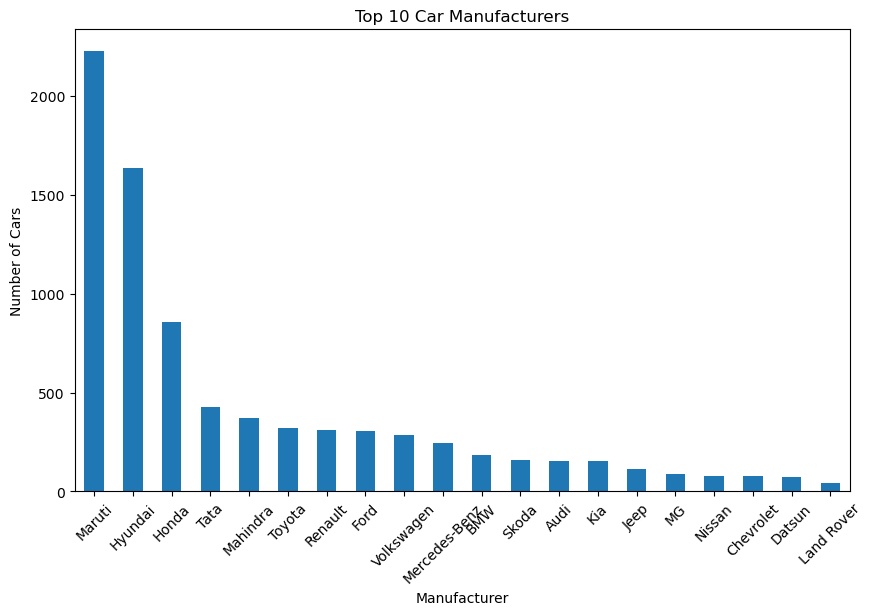

In [206]:
#Top 10 Car Manufacturers
plt.figure(figsize=(10,6))
complete_cars["oem"].value_counts().head(20).plot(kind="bar")
plt.title("Top 10 Car Manufacturers")
plt.xlabel("Manufacturer")
plt.ylabel("Number of Cars")
plt.xticks(rotation=45)
plt.show()

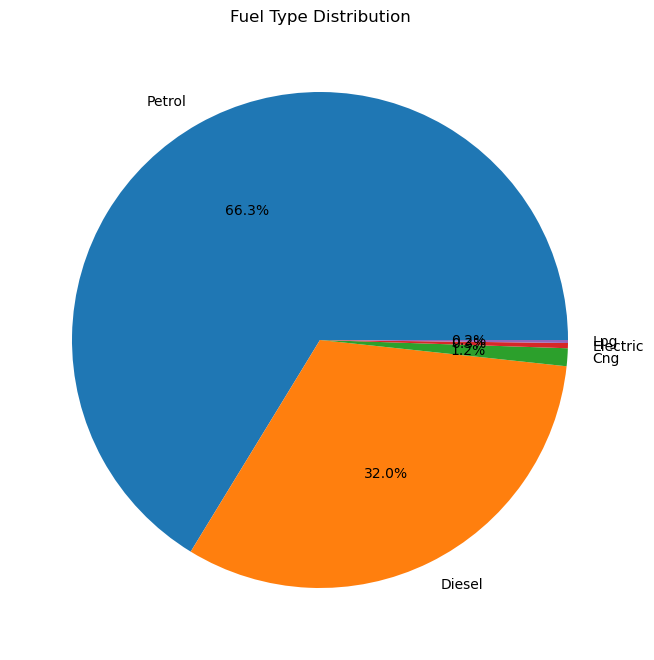

In [207]:
#Fuel Type Distribution
plt.figure(figsize=(8,20))
complete_cars["ft"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.ylabel("")
plt.title("Fuel Type Distribution")
plt.show()

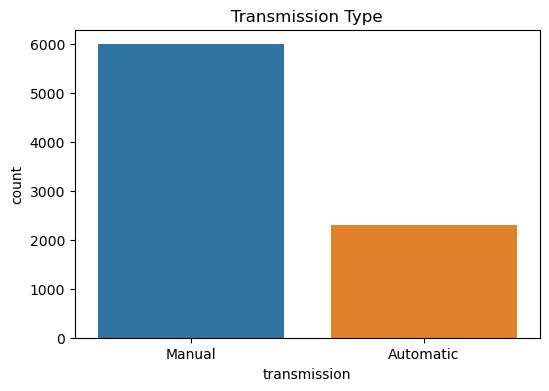

In [208]:
#Transmission Distribution
plt.figure(figsize=(6,4))
sns.countplot(data=complete_cars, x="transmission")
plt.title("Transmission Type")
plt.show()

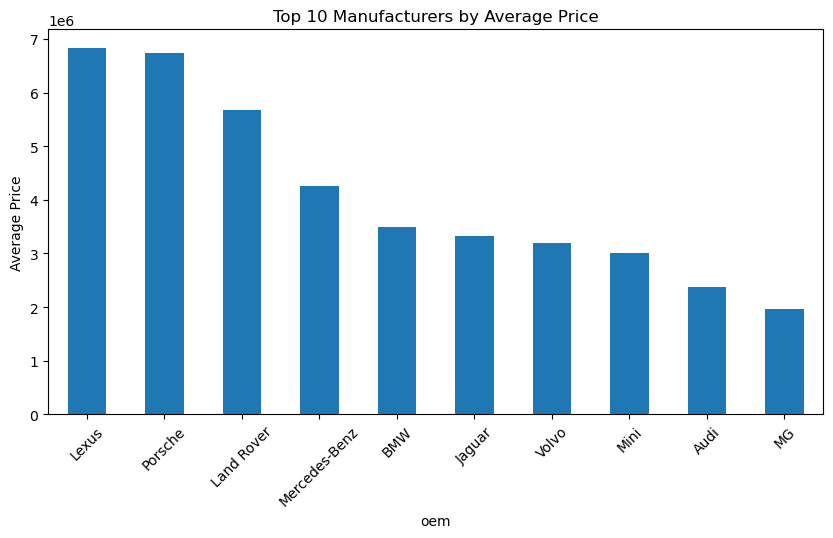

In [209]:
# Average Price by Manufacturer
top = complete_cars.groupby("oem")["price"].mean().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,5))
top.plot(kind="bar")
plt.title("Top 10 Manufacturers by Average Price")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.show()

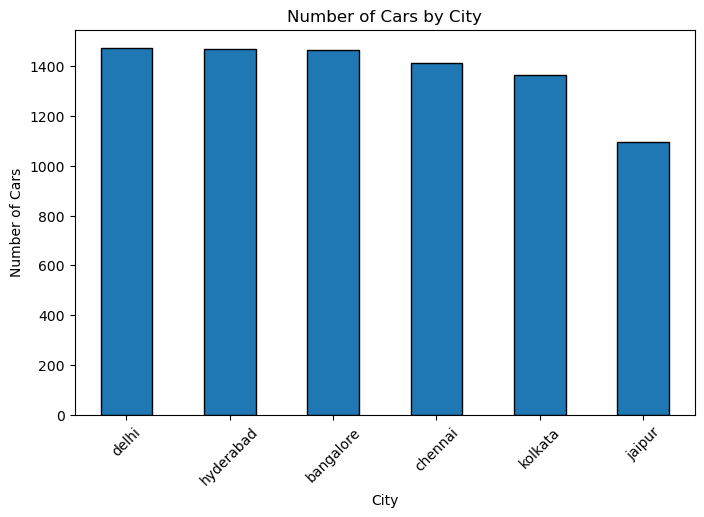

In [210]:
#number of cars by city
city_counts = complete_cars["city"].value_counts()
plt.figure(figsize=(8,5))
city_counts.plot(kind="bar", edgecolor="black")
plt.title("Number of Cars by City")
plt.xlabel("City")
plt.ylabel("Number of Cars")
plt.xticks(rotation=45)
plt.show()

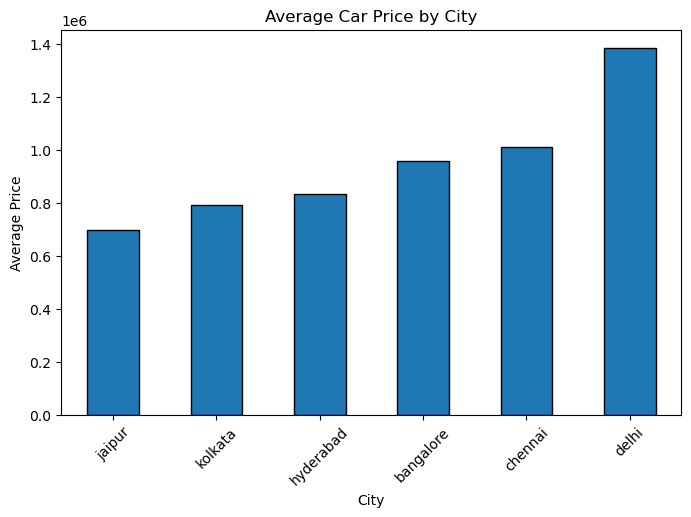

In [211]:
# average price by city
city_price = complete_cars.groupby("city")["price"].mean().sort_values()
plt.figure(figsize=(8,5))
city_price.plot(kind="bar", edgecolor="black")
plt.title("Average Car Price by City")
plt.xlabel("City")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.show()

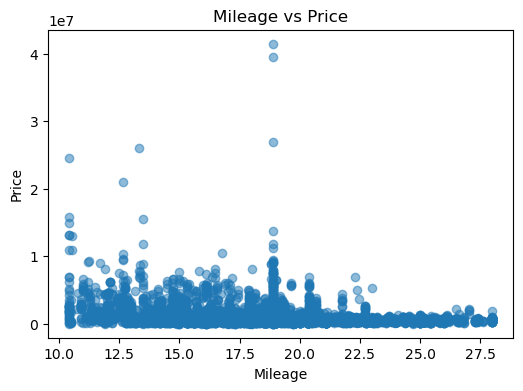

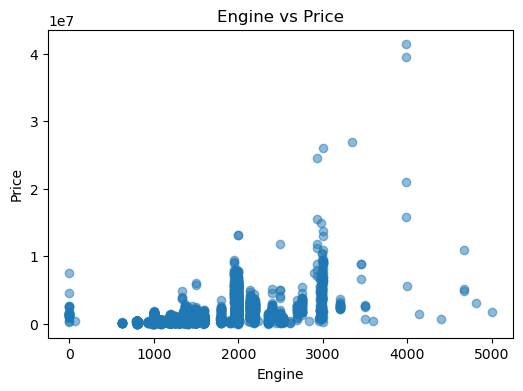

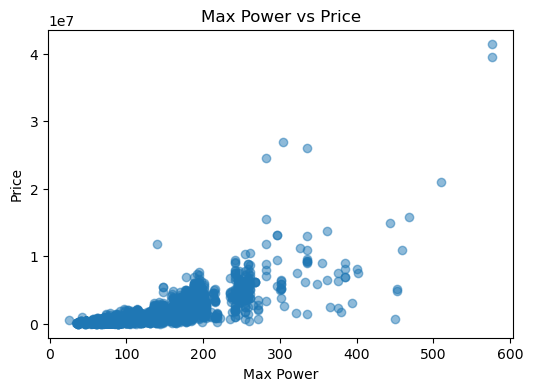

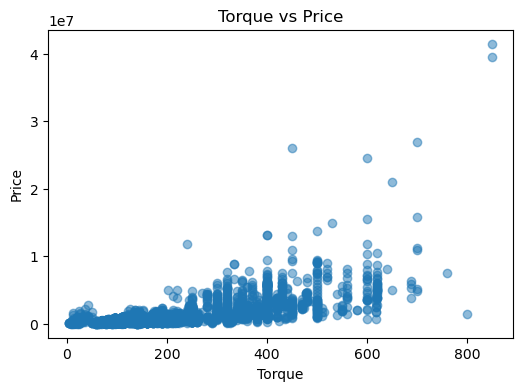

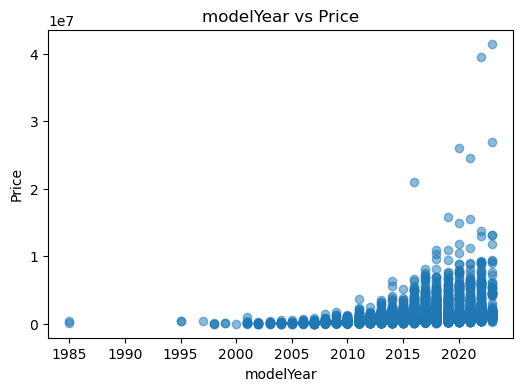

In [212]:
features = [
    "Mileage",
    "Engine",
    "Max Power",
    "Torque",
    "modelYear"
]
for col in features:
    plt.figure(figsize=(6,4))
    plt.scatter(complete_cars[col], complete_cars["price"], alpha=0.5)
    plt.xlabel(col)
    plt.ylabel("Price")
    plt.title(f"{col} vs Price")
    plt.show()

## Feature Engineering

In [213]:
feature_df = complete_cars.copy()

In [214]:
X = feature_df.drop(columns=["price"])
y = feature_df["price"]

In [215]:
print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (8281, 229)
y Shape: (8281,)


In [216]:
# create safety columns

In [217]:
safety_cols = [
    "Centeral Locking",
    "Child Safety Locks",
    "Side Impact Beams",
    "Front Impact Beams",
    "Engine Immobilizer",
    "Anti Theft Device",
    "Anti Lock Braking System",
    "Power Door Locks",
    "Driver Air Bag",
    "Passenger Air Bag",
    "Seat Belt Warning",
    "Engine Check Warning",
    "Crash Sensor",
    "Ebd",
    "Speed Sensing Auto Door Lock",
    "Pretensioners And Force Limiter Seatbelts",
    "Impact Sensing Auto Door Lock",
    "No Of Airbags",
    "Anti Theft Alarm",
    "Isofix Child Seat Mounts",
    "Tailgate Ajar",
    "Brake Assist",
    "Side Air Bag Front",
    "Side Air Bag Rear",
    "Tyre Pressure Monitor",
    "Clutch Lock",
    "Knee Airbags",
    "Speed Alert",
    "Vehicle Stability Control System",
    "Eletronic Stability Control",
    "Traction Control",
    "Hill Assist",
    "Hill Descent Control",
    "Blind Spot Monitor",
    "Lane Watch Camera",
    "Sos Emergency Assistance"
]

In [218]:
existing_safety_cols = [
    col for col in safety_cols
    if col in complete_cars.columns
]
missing_safety_cols = [
    col for col in safety_cols
    if col not in complete_cars.columns
]
print("Total Safety Columns:", len(safety_cols))
print("Existing Safety Columns:", len(existing_safety_cols))
print("Missing Safety Columns:", len(missing_safety_cols))
print("\nMissing Columns:")
print(missing_safety_cols)

Total Safety Columns: 36
Existing Safety Columns: 36
Missing Safety Columns: 0

Missing Columns:
[]


In [219]:
for col in existing_safety_cols:
    print(f"{col}: {complete_cars[col].unique()}")

Centeral Locking: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Child Safety Locks: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Side Impact Beams: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Front Impact Beams: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Engine Immobilizer: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Anti Theft Device: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Anti Lock Braking System: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Power Door Locks: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Driver Air Bag: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Passenger Air Bag: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Seat Belt Warning: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Engine Check Warning: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Crash Sensor: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Ebd: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Speed Sensing Auto Door Lock: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Pretensioners And Force Limiter Seatbelt

In [220]:
# create safety_score
complete_cars["Safety_Score"] = complete_cars[existing_safety_cols].sum(axis=1)

In [221]:
complete_cars["Safety_Score"].value_counts().sort_index()

Safety_Score
0      96
1       5
2      53
3      73
4     207
5     150
6     163
7     175
8     335
9     351
10    238
11    260
12    264
13    482
14    754
15    359
16    511
17    697
18    594
19    705
20    445
21    296
22    247
23    144
24    174
25    121
26     85
27    113
28     83
29     46
30     19
31     18
32     10
34      1
35      5
36      2
Name: count, dtype: Int64

In [222]:
# create comfort columns

In [223]:
comfort_cols = [
    "Power Windows Front",
    "Power Windows Rear",
    "Remote Trunk Opener",
    "Remote Fuel Lid Opener",
    "Low Fuel Warning Light",
    "Accessory Power Outlet",
    "Vanity Mirror",
    "Rear Seat Headrest",
    "Cup Holders Front",
    "Air Conditioner",
    "Heater",
    "Glove Compartment",
    "Day Night Rear View Mirror",
    "Passenger Side Rear View Mirror",
    "Trunk Light",
    "Smart Access Card Entry",
    "Engine Start Stop Button",
    "Glove Box Cooling",
    "Cup Holders Rear",
    "Rear ACVents",
    "Air Quality Control",
    "Cruise Control",
    "Seat Lumbar Support",
    "Battery Saver",
    "Cigarette Lighter",
    "Rain Sensing Wiper",
    "Active Noise Cancellation",
    "Adjustable Headrest",
    "Hands Free Tailgate",
    "Anti Pinch Power Windows",
    "Power Boot",
    "Rear Folding Table",
    "Remote Engine Start Stop",
    "Remote Climate Control",
    "Remote Horn Light Control",
    "Heated Wing Mirror",
    "Real Time Vehicle Tracking",
    "Smart Key Band",
    "Find My Car Location"
]

In [224]:
existing_comfort_cols = [
    col for col in comfort_cols
    if col in complete_cars.columns
]
missing_comfort_cols = [
    col for col in comfort_cols
    if col not in complete_cars.columns
]
print("Total Comfort Columns:", len(comfort_cols))
print("Existing Comfort Columns:", len(existing_comfort_cols))
print("Missing Comfort Columns:", len(missing_comfort_cols))

print("\nMissing Columns:")
print(missing_comfort_cols)

Total Comfort Columns: 39
Existing Comfort Columns: 39
Missing Comfort Columns: 0

Missing Columns:
[]


In [225]:
for col in existing_comfort_cols:
    print(f"{col}: {complete_cars[col].unique()}")

Power Windows Front: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Power Windows Rear: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Remote Trunk Opener: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Remote Fuel Lid Opener: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Low Fuel Warning Light: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Accessory Power Outlet: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Vanity Mirror: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Rear Seat Headrest: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Cup Holders Front: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Air Conditioner: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Heater: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Glove Compartment: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Day Night Rear View Mirror: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Passenger Side Rear View Mirror: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Trunk Light: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Smart Access Card E

In [226]:
complete_cars["Comfort_Score"] = complete_cars[existing_comfort_cols].sum(axis=1)

In [227]:
complete_cars["Comfort_Score"].value_counts().sort_index()

Comfort_Score
0      68
1       2
2      12
3      11
4      10
5      24
6      31
7      82
8     165
9     348
10    229
11    208
12    421
13    575
14    913
15    755
16    672
17    418
18    556
19    606
20    510
21    389
22    422
23    216
24    248
25    196
26     68
27     52
28     39
29     11
30     14
31      6
32      1
34      3
Name: count, dtype: Int64

In [228]:
# create Interior & Infotainment category

In [229]:
infotainment_cols = [
    "Digital Odometer",
    "Electronic Multi Tripmeter",
    "Fabric Upholstery",
    "Digital Clock",
    "Navigation System",
    "Outside Temperature Display",
    "Cd Player",
    "Radio",
    "Speakers Front",
    "Speakers Rear",
    "Integrated2Din Audio",
    "Usb Auxiliary Input",
    "Bluetooth",
    "Touch Screen",
    "Number Of Speaker",
    "Voice Control",
    "Audio System Remote Control",
    "Leather Seats",
    "Leather Wrap Gear Shift Selector",
    "Dual Tone Dashboard",
    "Apple Car Play",
    "Android Auto",
    "Mirror Link",
    "Wireless Phone Charging",
    "Compass",
    "Touch Screen Size",
    "Cd Changer",
    "Dvd Player",
    "Internal Storage",
    "Rear Entertainment System",
    "Heads Up Display",
    "Cassette Player",
    "Wifi Connectivity"
]

In [230]:
existing_infotainment_cols = [
    col for col in infotainment_cols
    if col in complete_cars.columns
]
missing_infotainment_cols = [
    col for col in infotainment_cols
    if col not in complete_cars.columns
]
print("Total Infotainment Columns:", len(infotainment_cols))
print("Existing Infotainment Columns:", len(existing_infotainment_cols))
print("Missing Infotainment Columns:", len(missing_infotainment_cols))

print("\nMissing Columns:")
print(missing_infotainment_cols)

Total Infotainment Columns: 33
Existing Infotainment Columns: 33
Missing Infotainment Columns: 0

Missing Columns:
[]


In [231]:
for col in existing_infotainment_cols:
    print(f"{col}: {complete_cars[col].unique()}")

Digital Odometer: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Electronic Multi Tripmeter: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Fabric Upholstery: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Digital Clock: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Navigation System: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Outside Temperature Display: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Cd Player: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Radio: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Speakers Front: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Speakers Rear: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Integrated2Din Audio: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Usb Auxiliary Input: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Bluetooth: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Touch Screen: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Number Of Speaker: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Voice Control: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
A

In [232]:
complete_cars["Infotainment_Score"] = complete_cars[
    existing_infotainment_cols
].sum(axis=1)

In [233]:
complete_cars["Infotainment_Score"].value_counts().sort_index()

Infotainment_Score
0      91
1      81
2     114
3     398
4     420
5     110
6      68
7     280
8     446
9     442
10    437
11    698
12    621
13    957
14    577
15    687
16    738
17    414
18    335
19    179
20     79
21     54
22     28
23     12
24      8
25      3
26      4
Name: count, dtype: Int64

In [234]:
# create Exterior Category

In [235]:
exterior_cols = [
    "Adjustable Head Lights",
    "Manually Adjustable Exterior Rear View Mirror",
    "Wheel Covers",
    "Power Antenna",
    "Chrome Grille",
    "Halogen Headlamps",
    "Fog Lights Front",
    "Power Adjustable Exterior Rear View Mirror",
    "Electric Folding Rear View Mirror",
    "Rear Window Wiper",
    "Rear Window Washer",
    "Rear Window Defogger",
    "Alloy Wheels",
    "Integrated Antenna",
    "Outside Rear View Mirror Turn Indicators",
    "Roof Rail",
    "Tinted Glass",
    "Rear Spoiler",
    "Chrome Garnish",
    "Fog Lights Rear",
    "Sun Roof",
    "Automatic Driving Lights",
    "Automatic Head Lamps",
    "LEDTaillights",
    "Dual Tone Body Colour",
    "LEDDRLs",
    "LEDHeadlights",
    "Cornering Headlamps",
    "Cornering Foglamps",
    "Moon Roof",
    "Projector Headlamps",
    "Xenon Headlamps",
    "Smoke Headlamps",
    "LEDFog Lamps",
    "Side Stepper",
    "Headlamp Washers",
    "Roof Carrier",
    "Removable Convertible Top"
]

In [236]:
existing_exterior_cols = [
    col for col in exterior_cols
    if col in complete_cars.columns
]
missing_exterior_cols = [
    col for col in exterior_cols
    if col not in complete_cars.columns
]
print("Total Exterior Columns:", len(exterior_cols))
print("Existing Exterior Columns:", len(existing_exterior_cols))
print("Missing Exterior Columns:", len(missing_exterior_cols))

print("\nMissing Columns:")
print(missing_exterior_cols)

Total Exterior Columns: 38
Existing Exterior Columns: 38
Missing Exterior Columns: 0

Missing Columns:
[]


In [237]:
for col in existing_exterior_cols:
    print(f"{col}: {complete_cars[col].unique()}")

Adjustable Head Lights: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Manually Adjustable Exterior Rear View Mirror: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Wheel Covers: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Power Antenna: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Chrome Grille: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Halogen Headlamps: <IntegerArray>
[1, 0]
Length: 2, dtype: Int8
Fog Lights Front: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Power Adjustable Exterior Rear View Mirror: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Electric Folding Rear View Mirror: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Rear Window Wiper: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Rear Window Washer: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Rear Window Defogger: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Alloy Wheels: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Integrated Antenna: <IntegerArray>
[0, 1]
Length: 2, dtype: Int8
Outside Rear View Mirror Turn Indicators: <I

In [238]:
complete_cars["Exterior_Score"] = complete_cars[
    existing_exterior_cols
].sum(axis=1)

In [239]:
complete_cars["Exterior_Score"].value_counts().sort_index()

Exterior_Score
0      90
1       2
2      22
3     114
4     287
5     540
6     501
7     623
8     413
9     510
10    623
11    679
12    600
13    721
14    454
15    549
16    443
17    254
18    209
19    233
20    156
21     86
22     56
23     78
24     17
25     16
26      5
Name: count, dtype: Int64

In [240]:
grouped_cols = (safety_cols + comfort_cols + infotainment_cols + exterior_cols)
remaining_cols = [
    col for col in X.columns
    if col not in grouped_cols
]
print("Total Original Input Features:", X.shape[1])
print("Already Grouped Features:", len(grouped_cols))
print("Remaining Features:", len(remaining_cols))

print("\nRemaining Columns:")
for col in remaining_cols:
    print(col)

Total Original Input Features: 229
Already Grouped Features: 146
Remaining Features: 83

Remaining Columns:
ft
bt
km
transmission
ownerNo
owner
oem
model
modelYear
variantName
Registration Year
Insurance Validity
Fuel Type
overview_Seats
Kms Driven
RTO
Ownership
Engine Displacement
Year of Manufacture
Power Steering
Rear Seat Belts
Door Ajar Warning
Adjustable Seats
Centrally Mounted Fuel Tank
Multifunction Steering Wheel
Gear Shift Indicator
Luggage Hook And Net
Adjustable Steering
Tachometer
Leather Steering Wheel
Height Adjustable Driver Seat
Keyless Entry
Follow Me Home Headlamps
Rear Camera
Driving Experience Control Eco
Rear Reading Lamp
Rear Seat Centre Arm Rest
Height Adjustable Front Seat Belts
Lane Change Indicator
Steering Wheel Gearshift Paddles
Drive Modes
Ventilated Seats
View360Camera
Geo Fence Alert
Steering Mounted Tripmeter
Power Folding3rd Row Seat
Mileage
Engine
Max Power
Torque
Seats
Color
Engine Type
Displacement
Max Torque
No of Cylinder
Values per Cylinder
Value

In [241]:
# Create Engine & Performance Column List

In [242]:
engine_cols = [
    "Engine Displacement",
    "Mileage",
    "Engine",
    "Max Power",
    "Torque",
    "Engine Type",
    "Displacement",
    "Max Torque",
    "No of Cylinder",
    "Values per Cylinder",
    "Value Configuration",
    "Fuel Suppy System",
    "Turbo Charger",
    "Super Charger",
    "Top Speed",
    "Acceleration"
]

In [243]:
existing_engine_cols = [
    col for col in engine_cols
    if col in complete_cars.columns
]
missing_engine_cols = [
    col for col in engine_cols
    if col not in complete_cars.columns
]
print("Total Engine Columns:", len(engine_cols))
print("Existing Engine Columns:", len(existing_engine_cols))
print("Missing Engine Columns:", len(missing_engine_cols))

print("\nMissing Columns:")
print(missing_engine_cols)

Total Engine Columns: 16
Existing Engine Columns: 16
Missing Engine Columns: 0

Missing Columns:
[]


In [244]:
for col in existing_engine_cols:
    print(
        f"{col:<25} "
        f"Dtype: {str(complete_cars[col].dtype):<10} "
        f"Unique Count: {complete_cars[col].nunique()}"
    )

Engine Displacement       Dtype: float64    Unique Count: 150
Mileage                   Dtype: float64    Unique Count: 483
Engine                    Dtype: float64    Unique Count: 150
Max Power                 Dtype: float64    Unique Count: 458
Torque                    Dtype: float64    Unique Count: 269
Engine Type               Dtype: object     Unique Count: 508
Displacement              Dtype: Int64      Unique Count: 150
Max Torque                Dtype: float64    Unique Count: 269
No of Cylinder            Dtype: float64    Unique Count: 8
Values per Cylinder       Dtype: float64    Unique Count: 5
Value Configuration       Dtype: object     Unique Count: 14
Fuel Suppy System         Dtype: object     Unique Count: 82
Turbo Charger             Dtype: object     Unique Count: 10
Super Charger             Dtype: object     Unique Count: 6
Top Speed                 Dtype: float64    Unique Count: 163
Acceleration              Dtype: float64    Unique Count: 211


In [245]:
engine_duplicate_check = pd.DataFrame({
    "Engine_Displacement_vs_Engine":
        complete_cars["Engine Displacement"].eq(
            complete_cars["Engine"]
        ),

    "Engine_Displacement_vs_Displacement":
        complete_cars["Engine Displacement"].eq(
            complete_cars["Displacement"]
        ),

    "Engine_vs_Displacement":
        complete_cars["Engine"].eq(
            complete_cars["Displacement"]
        ),

    "Torque_vs_Max_Torque":
        complete_cars["Torque"].eq(
            complete_cars["Max Torque"]
        )
})

engine_duplicate_check.mean() * 100

Engine_Displacement_vs_Engine          100.0
Engine_Displacement_vs_Displacement    100.0
Engine_vs_Displacement                 100.0
Torque_vs_Max_Torque                   100.0
dtype: Float64

In [246]:
print("Zero Engine Displacement:",(complete_cars["Engine Displacement"] == 0).sum())
print( "Zero Max Torque:", (complete_cars["Max Torque"] == 0).sum())

Zero Engine Displacement: 26
Zero Max Torque: 0


In [247]:
# create power_per_CC
complete_cars["Power_Per_CC"] = np.where(complete_cars["Engine Displacement"] > 0,complete_cars["Max Power"] / complete_cars["Engine Displacement"],np.nan)

In [248]:
# create torque_per_cc
complete_cars["Torque_Per_CC"] = np.where(complete_cars["Engine Displacement"] > 0,complete_cars["Max Torque"] / complete_cars["Engine Displacement"],np.nan)

In [249]:
complete_cars[
    [
        "Engine Displacement",
        "Max Power",
        "Max Torque",
        "Power_Per_CC",
        "Torque_Per_CC"
    ]
].head(10)

,Engine Displacement,Max Power,Max Torque,Power_Per_CC,Torque_Per_CC
0,998.0,67.04,90.00,0.067174,0.090180
1,1497.0,121.31,150.00,0.081035,0.100200
2,1199.0,84.00,114.00,0.070058,0.095079
3,1197.0,81.86,113.75,0.068388,0.095029
4,1248.0,88.50,200.00,0.070913,0.160256
5,1956.0,170.00,350.00,0.086912,0.178937
6,1198.0,67.00,104.00,0.055927,0.086811
7,998.0,118.35,171.60,0.118587,0.171944
8,1462.0,103.25,138.00,0.070622,0.094391
9,1199.0,84.00,114.00,0.070058,0.095079


In [250]:
print(
    "Infinite Power_Per_CC:",
    np.isinf(complete_cars["Power_Per_CC"]).sum()
)
print(
    "Infinite Torque_Per_CC:",
    np.isinf(complete_cars["Torque_Per_CC"]).sum()
)

Infinite Power_Per_CC: 0
Infinite Torque_Per_CC: 0


In [251]:
print(
    "Missing Power_Per_CC:",
    complete_cars["Power_Per_CC"].isnull().sum()
)
print(
    "Missing Torque_Per_CC:",
    complete_cars["Torque_Per_CC"].isnull().sum()
)

Missing Power_Per_CC: 26
Missing Torque_Per_CC: 26


In [252]:
complete_cars["Power_Per_CC"] = complete_cars[
    "Power_Per_CC"
].fillna(
    complete_cars["Power_Per_CC"].median()
)
complete_cars["Torque_Per_CC"] = complete_cars[
    "Torque_Per_CC"
].fillna(
    complete_cars["Torque_Per_CC"].median()
)

In [253]:
print(
    "Missing Power_Per_CC:",
    complete_cars["Power_Per_CC"].isnull().sum()
)
print(
    "Missing Torque_Per_CC:",
    complete_cars["Torque_Per_CC"].isnull().sum()
)

Missing Power_Per_CC: 0
Missing Torque_Per_CC: 0


In [254]:
# Dimensions & Capacity

In [255]:
dimension_cols = [
    "overview_Seats",
    "Adjustable Seats",
    "Height Adjustable Driver Seat",
    "Height Adjustable Front Seat Belts",
    "Ventilated Seats",
    "Power Folding3rd Row Seat",
    "Seats",
    "Length",
    "Width",
    "Height",
    "Wheel Base",
    "Front Tread",
    "Rear Tread",
    "Kerb Weight",
    "Gross Weight",
    "Seating Capacity",
    "Turning Radius",
    "No Door Numbers",
    "Cargo Volumn",
    "Wheel Size"
]

In [256]:
existing_dimension_cols = [
    col for col in dimension_cols
    if col in complete_cars.columns
]
missing_dimension_cols = [
    col for col in dimension_cols
    if col not in complete_cars.columns
]

print("Total Dimension Columns:", len(dimension_cols))
print("Existing Dimension Columns:", len(existing_dimension_cols))
print("Missing Dimension Columns:", len(missing_dimension_cols))

print("\nMissing Columns:")
print(missing_dimension_cols)

Total Dimension Columns: 20
Existing Dimension Columns: 20
Missing Dimension Columns: 0

Missing Columns:
[]


In [257]:
for col in existing_dimension_cols:
    print(
        f"{col:<40} "
        f"Dtype: {str(complete_cars[col].dtype):<10} "
        f"Unique Count: {complete_cars[col].nunique()}"
    )

overview_Seats                           Dtype: float64    Unique Count: 8
Adjustable Seats                         Dtype: Int8       Unique Count: 2
Height Adjustable Driver Seat            Dtype: Int8       Unique Count: 2
Height Adjustable Front Seat Belts       Dtype: Int8       Unique Count: 2
Ventilated Seats                         Dtype: Int8       Unique Count: 2
Power Folding3rd Row Seat                Dtype: Int8       Unique Count: 2
Seats                                    Dtype: Int64      Unique Count: 8
Length                                   Dtype: float64    Unique Count: 345
Width                                    Dtype: float64    Unique Count: 223
Height                                   Dtype: float64    Unique Count: 252
Wheel Base                               Dtype: float64    Unique Count: 183
Front Tread                              Dtype: float64    Unique Count: 133
Rear Tread                               Dtype: float64    Unique Count: 153
Kerb Weight  

In [258]:
seat_duplicate_check = pd.DataFrame({
    "overview_Seats_vs_Seats":
        complete_cars["overview_Seats"].eq(
            complete_cars["Seats"]
        ),

    "overview_Seats_vs_Seating_Capacity":
        complete_cars["overview_Seats"].eq(
            complete_cars["Seating Capacity"]
        ),

    "Seats_vs_Seating_Capacity":
        complete_cars["Seats"].eq(
            complete_cars["Seating Capacity"]
        )
})

seat_duplicate_check.mean() * 100

overview_Seats_vs_Seats               100.0
overview_Seats_vs_Seating_Capacity    100.0
Seats_vs_Seating_Capacity             100.0
dtype: Float64

In [259]:
# Create Car_Volume
complete_cars["Car_Volume"] = (
    complete_cars["Length"]
    * complete_cars["Width"]
    * complete_cars["Height"]
)

In [260]:
complete_cars[
    ["Length", "Width", "Height", "Car_Volume"]
].head(10)

,Length,Width,Height,Car_Volume
0,3715.0,1635.0,1565.0,9.505849e+09
1,3998.0,1765.0,1647.0,1.162201e+10
2,3746.0,1647.0,1535.0,9.470431e+09
3,3995.0,1660.0,1520.0,1.008018e+10
4,4300.0,1785.0,1595.0,1.224242e+10
5,4395.0,1818.0,1640.0,1.310378e+10
6,3785.0,1635.0,1490.0,9.220828e+09
7,3995.0,1770.0,1605.0,1.134920e+10
8,4490.0,1730.0,1485.0,1.153503e+10
9,3746.0,1647.0,1535.0,9.470431e+09


In [261]:
print(
    "Missing Car_Volume:",
    complete_cars["Car_Volume"].isnull().sum()
)

print(
    "Infinite Car_Volume:",
    np.isinf(complete_cars["Car_Volume"]).sum()
)

Missing Car_Volume: 0
Infinite Car_Volume: 0


In [262]:
complete_cars["Car_Volume"].describe()

count    8.281000e+03
mean     1.126118e+10
std      2.246296e+09
min      6.747372e+09
25%      9.811777e+09
50%      1.076661e+10
75%      1.224242e+10
max      2.156419e+10
Name: Car_Volume, dtype: float64

In [263]:
complete_cars["Car_Volume"] = (
    complete_cars["Length"]
    * complete_cars["Width"]
    * complete_cars["Height"]
) / 1e9

In [264]:
complete_cars[
    ["Length", "Width", "Height", "Car_Volume"]
].head()

,Length,Width,Height,Car_Volume
0,3715.0,1635.0,1565.0,9.505849
1,3998.0,1765.0,1647.0,11.622006
2,3746.0,1647.0,1535.0,9.470431
3,3995.0,1660.0,1520.0,10.080184
4,4300.0,1785.0,1595.0,12.242422


In [265]:
grouped_cols = (
    safety_cols
    + comfort_cols
    + infotainment_cols
    + exterior_cols
    + engine_cols
    + dimension_cols
)

remaining_cols = [
    col for col in X.columns
    if col not in grouped_cols
]
print("Remaining Features:", len(remaining_cols))

for col in remaining_cols:
    print(
        f"{col:<40} "
        f"Dtype: {str(complete_cars[col].dtype):<10} "
        f"Unique Count: {complete_cars[col].nunique()}"
    )

Remaining Features: 47
ft                                       Dtype: object     Unique Count: 5
bt                                       Dtype: object     Unique Count: 11
km                                       Dtype: int64      Unique Count: 4045
transmission                             Dtype: object     Unique Count: 2
ownerNo                                  Dtype: Int8       Unique Count: 6
owner                                    Dtype: object     Unique Count: 6
oem                                      Dtype: object     Unique Count: 33
model                                    Dtype: object     Unique Count: 315
modelYear                                Dtype: Int64      Unique Count: 29
variantName                              Dtype: object     Unique Count: 2157
Registration Year                        Dtype: Int64      Unique Count: 22
Insurance Validity                       Dtype: object     Unique Count: 7
Fuel Type                                Dtype: object     Unique

In [266]:
# Driving_Technology_Score

In [267]:
driving_technology_cols = [
    "Multifunction Steering Wheel",
    "Gear Shift Indicator",
    "Adjustable Steering",
    "Leather Steering Wheel",
    "Keyless Entry",
    "Follow Me Home Headlamps",
    "Rear Camera",
    "Driving Experience Control Eco",
    "Lane Change Indicator",
    "Steering Wheel Gearshift Paddles",
    "Drive Modes",
    "View360Camera",
    "Geo Fence Alert",
    "Steering Mounted Tripmeter"
]

In [268]:
existing_driving_technology_cols = [
    col for col in driving_technology_cols
    if col in complete_cars.columns
]
missing_driving_technology_cols = [
    col for col in driving_technology_cols
    if col not in complete_cars.columns
]
print("Total Driving Technology Columns:",len(driving_technology_cols))
print("Existing Driving Technology Columns:",len(existing_driving_technology_cols))
print("Missing Driving Technology Columns:",len(missing_driving_technology_cols))

print("\nMissing Columns:")
print(missing_driving_technology_cols)

Total Driving Technology Columns: 14
Existing Driving Technology Columns: 14
Missing Driving Technology Columns: 0

Missing Columns:
[]


In [269]:
complete_cars["Driving_Technology_Score"] = complete_cars[
    existing_driving_technology_cols
].sum(axis=1)

In [270]:
print(
    "Minimum Driving Technology Score:",
    complete_cars["Driving_Technology_Score"].min()
)
print(
    "Maximum Driving Technology Score:",
    complete_cars["Driving_Technology_Score"].max()
)
complete_cars[
    "Driving_Technology_Score"
].value_counts().sort_index()

Minimum Driving Technology Score: 0
Maximum Driving Technology Score: 12


Driving_Technology_Score
0      662
1      678
2      732
3     1093
4     1479
5     1083
6      957
7      658
8      458
9      207
10     156
11      97
12      21
Name: count, dtype: Int64

In [271]:
candidate_features = [
    # Basic car information
    "ft",
    "bt",
    "km",
    "transmission",
    "ownerNo",
    "oem",
    "model",
    "modelYear",
    "variantName",
    "Insurance Validity",
    "RTO",
    "city",

    # Engine and performance
    "Engine Displacement",
    "Mileage",
    "Max Power",
    "Max Torque",
    "No of Cylinder",
    "Values per Cylinder",
    "Value Configuration",
    "Fuel Suppy System",
    "Turbo Charger",
    "Super Charger",
    "Top Speed",
    "Acceleration",

    # Dimensions
    "Seats",
    "Length",
    "Width",
    "Height",
    "Wheel Base",
    "Front Tread",
    "Rear Tread",
    "Kerb Weight",
    "Gross Weight",
    "Turning Radius",
    "No Door Numbers",
    "Cargo Volumn",
    "Wheel Size",

    # Mechanical
    "Gear Box",
    "Drive Type",
    "Steering Type",
    "Front Brake Type",
    "Rear Brake Type",
    "Tyre Type",

    # Engineered features
    "Safety_Score",
    "Comfort_Score",
    "Infotainment_Score",
    "Exterior_Score",
    "Power_Per_CC",
    "Torque_Per_CC",
    "Car_Volume",
    "Driving_Technology_Score"
]

In [272]:
candidate_df = complete_cars[candidate_features + ["price"]].copy()

In [273]:
print("Candidate Dataset Shape:", candidate_df.shape)

Candidate Dataset Shape: (8281, 52)


In [274]:
candidate_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8281 entries, 0 to 8368
Data columns (total 52 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ft                        8281 non-null   object 
 1   bt                        8281 non-null   object 
 2   km                        8281 non-null   int64  
 3   transmission              8281 non-null   object 
 4   ownerNo                   8281 non-null   Int8   
 5   oem                       8281 non-null   object 
 6   model                     8281 non-null   object 
 7   modelYear                 8281 non-null   Int64  
 8   variantName               8281 non-null   object 
 9   Insurance Validity        8281 non-null   object 
 10  RTO                       8281 non-null   object 
 11  city                      8281 non-null   object 
 12  Engine Displacement       8281 non-null   float64
 13  Mileage                   8281 non-null   float64
 14  Max Power    

In [275]:
# seperate X and y again

In [276]:
X_candidate = candidate_df.drop(columns=["price"])
y_candidate = candidate_df["price"]

In [277]:
numerical_cols = X_candidate.select_dtypes(include=["number"]).columns.tolist()

categorical_cols = X_candidate.select_dtypes(include=["object", "category"]).columns.tolist()

In [278]:
print("Numerical Columns:", len(numerical_cols))
print("Categorical Columns:", len(categorical_cols))

print("\nNumerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

Numerical Columns: 32
Categorical Columns: 19

Numerical Columns:
['km', 'ownerNo', 'modelYear', 'Engine Displacement', 'Mileage', 'Max Power', 'Max Torque', 'No of Cylinder', 'Values per Cylinder', 'Top Speed', 'Acceleration', 'Seats', 'Length', 'Width', 'Height', 'Wheel Base', 'Front Tread', 'Rear Tread', 'Kerb Weight', 'Gross Weight', 'Turning Radius', 'No Door Numbers', 'Cargo Volumn', 'Wheel Size', 'Safety_Score', 'Comfort_Score', 'Infotainment_Score', 'Exterior_Score', 'Power_Per_CC', 'Torque_Per_CC', 'Car_Volume', 'Driving_Technology_Score']

Categorical Columns:
['ft', 'bt', 'transmission', 'oem', 'model', 'variantName', 'Insurance Validity', 'RTO', 'city', 'Value Configuration', 'Fuel Suppy System', 'Turbo Charger', 'Super Charger', 'Gear Box', 'Drive Type', 'Steering Type', 'Front Brake Type', 'Rear Brake Type', 'Tyre Type']


In [279]:
X_train, X_test, y_train, y_test = train_test_split(X_candidate, y_candidate, test_size=0.2, random_state=42)

In [280]:
print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)  

print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (6624, 51)
X_test Shape: (1657, 51)
y_train Shape: (6624,)
y_test Shape: (1657,)


In [281]:
# Columns for Target Encoding
target_encode_cols = [
    col for col in categorical_cols
    if col != ["oem","variantName"]
]

In [282]:
# Columns for Frequency Encoding
frequency_encode_cols = [
    "oem",
    "variantName"
]

In [283]:
X_train_encoded = X_train.copy()
X_test_encoded = X_test.copy()

In [284]:
#Frequency Encoding
for col in frequency_encode_cols:
    freq_map = X_train[col].value_counts(normalize=True)

    X_train_encoded[col] = X_train[col].map(freq_map)
    X_test_encoded[col] = X_test[col].map(freq_map)

    # Handle unseen categories
    X_test_encoded[col] = X_test_encoded[col].fillna(0)

In [285]:
target_encoder = TargetEncoder(target_type="continuous",random_state=42)

In [286]:
X_train_encoded[target_encode_cols] = target_encoder.fit_transform(X_train[target_encode_cols],y_train)
X_test_encoded[target_encode_cols] = target_encoder.transform( X_test[target_encode_cols])

In [287]:
print("X_train_encoded Shape:", X_train_encoded.shape)
print("X_test_encoded Shape:", X_test_encoded.shape)

print("\nRemaining Object Columns:")
print(X_train_encoded.select_dtypes(include=["object"]).columns.tolist())

X_train_encoded Shape: (6624, 51)
X_test_encoded Shape: (1657, 51)

Remaining Object Columns:
[]


In [288]:
X_train_encoded[categorical_cols].head()

,ft,bt,transmission,oem,model,variantName,Insurance Validity,RTO,city,Value Configuration,Fuel Suppy System,Turbo Charger,Super Charger,Gear Box,Drive Type,Steering Type,Front Brake Type,Rear Brake Type,Tyre Type
7075,7.751495e+05,4.454602e+05,5.823526e+05,495279.223333,148314.864292,170188.733563,8.031925e+05,5.209057e+05,800449.121907,489695.549592,5.087365e+05,534932.714041,837221.228047,5.115362e+05,650147.415820,944540.982549,991748.410464,6.251054e+05,970286.999296
5443,7.980398e+05,4.439369e+05,1.945222e+06,543389.825683,393192.170973,384422.134536,8.157843e+05,6.074997e+05,842066.920194,989028.523676,5.917951e+05,535426.425060,846425.078578,5.136773e+05,653639.083816,953067.992850,990818.032047,6.256912e+05,986766.822188
2147,7.980398e+05,4.439369e+05,5.900833e+05,614201.939958,572681.217223,426881.713654,1.272991e+06,1.191497e+06,990594.968057,989028.523676,5.186685e+05,535426.425060,846425.078578,5.136773e+05,653639.083816,953067.992850,990818.032047,6.256912e+05,634233.107065
5813,1.348232e+06,1.046917e+06,5.945297e+05,610357.567922,740337.356384,127989.158735,8.086434e+05,1.005110e+06,852420.267337,986538.733401,1.184625e+06,538599.867154,851462.571485,5.175670e+05,659136.257519,954206.852447,946685.702343,2.276936e+05,982216.350743
5915,1.348232e+06,4.487318e+05,5.945297e+05,610357.567922,561453.188290,386289.516437,8.086434e+05,4.758993e+05,731245.729960,986538.733401,1.184625e+06,538599.867154,851462.571485,1.134074e+06,659136.257519,954206.852447,988673.177543,2.206255e+06,982216.350743


In [289]:
# Mutual Information Feature Selection
mi_scores = mutual_info_regression(X_train_encoded,y_train,random_state=42)

In [290]:
mi_results = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "MI_Score": mi_scores
})

In [291]:
mi_results = mi_results.sort_values(by="MI_Score",ascending=False).reset_index(drop=True)

In [292]:
mi_results.head(20)

,Feature,MI_Score
0,Car_Volume,0.918928
1,model,0.892704
2,Max Power,0.887106
3,variantName,0.858673
4,Width,0.854539
5,Max Torque,0.809929
6,Length,0.809021
7,Power_Per_CC,0.790770
8,Wheel Base,0.787525
9,Kerb Weight,0.732937


In [293]:
rf_selector = RandomForestRegressor(n_estimators=200,random_state=42,n_jobs=-1)
rf_selector.fit(X_train_encoded, y_train)

,n_estimators,200
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [294]:
rf_results = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "RF_Importance": rf_selector.feature_importances_
})
rf_results = rf_results.sort_values(
    by="RF_Importance",
    ascending=False
).reset_index(drop=True)

In [295]:
rf_results.head(20)

,Feature,RF_Importance
0,Max Power,0.553619
1,model,0.121113
2,modelYear,0.064716
3,Gear Box,0.043187
4,variantName,0.032849
5,Height,0.027360
6,Car_Volume,0.016905
7,Max Torque,0.013344
8,Safety_Score,0.010329
9,Length,0.010309


In [296]:
combined_results = mi_results.merge(
    rf_results,
    on="Feature"
)

combined_results["MI_Rank"] = (
    combined_results["MI_Score"]
    .rank(ascending=False)
)

combined_results["RF_Rank"] = (
    combined_results["RF_Importance"]
    .rank(ascending=False)
)

combined_results["Average_Rank"] = (
    combined_results["MI_Rank"]
    + combined_results["RF_Rank"]
) / 2

combined_results = combined_results.sort_values(
    by="Average_Rank"
).reset_index(drop=True)

combined_results.head(30)

,Feature,MI_Score,RF_Importance,MI_Rank,RF_Rank,Average_Rank
0,model,0.892704,0.121113,2.0,2.0,2.0
1,Max Power,0.887106,0.553619,3.0,1.0,2.0
2,Car_Volume,0.918928,0.016905,1.0,7.0,4.0
3,variantName,0.858673,0.032849,4.0,5.0,4.5
4,Max Torque,0.809929,0.013344,6.0,8.0,7.0
5,Length,0.809021,0.010309,7.0,10.0,8.5
6,Height,0.683397,0.027360,12.0,6.0,9.0
7,Kerb Weight,0.732937,0.007452,10.0,13.0,11.5
8,Safety_Score,0.606231,0.010329,14.0,9.0,11.5
9,Power_Per_CC,0.790770,0.004300,8.0,15.0,11.5


In [297]:
perm_result = permutation_importance(
    rf_selector,
    X_test_encoded,
    y_test,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

In [298]:
perm_results = pd.DataFrame({
    "Feature": X_test_encoded.columns,
    "Permutation_Importance": perm_result.importances_mean
})

perm_results = perm_results.sort_values(
    by="Permutation_Importance",
    ascending=False
).reset_index(drop=True)

In [299]:
perm_results.head(30)

,Feature,Permutation_Importance
0,Max Power,0.634550
1,modelYear,0.167118
2,model,0.154218
3,Height,0.042016
4,Car_Volume,0.032375
5,Length,0.014149
6,Kerb Weight,0.012188
7,Acceleration,0.007238
8,variantName,0.006055
9,Gear Box,0.005675


In [300]:
final_ranking = (
    mi_results
    .merge(rf_results, on="Feature")
    .merge(perm_results, on="Feature")
)

In [301]:
final_ranking["MI_Rank"] = (
    final_ranking["MI_Score"]
    .rank(ascending=False)
)
final_ranking["RF_Rank"] = (
    final_ranking["RF_Importance"]
    .rank(ascending=False)
)
final_ranking["Permutation_Rank"] = (
    final_ranking["Permutation_Importance"]
    .rank(ascending=False)
)

In [302]:
final_ranking["Average_Rank"] = (
    final_ranking["MI_Rank"]
    + final_ranking["RF_Rank"]
    + final_ranking["Permutation_Rank"]
) / 3

In [303]:
final_ranking = final_ranking.sort_values(
    by="Average_Rank"
).reset_index(drop=True)

In [304]:
final_ranking[
    [
        "Feature",
        "MI_Rank",
        "RF_Rank",
        "Permutation_Rank",
        "Average_Rank"
    ]
].head(30)

,Feature,MI_Rank,RF_Rank,Permutation_Rank,Average_Rank
0,Max Power,3.0,1.0,1.0,1.666667
1,model,2.0,2.0,3.0,2.333333
2,Car_Volume,1.0,7.0,5.0,4.333333
3,variantName,4.0,5.0,9.0,6.000000
4,Height,12.0,6.0,4.0,7.333333
5,Length,7.0,10.0,6.0,7.666667
6,Kerb Weight,10.0,13.0,7.0,10.000000
7,modelYear,29.0,3.0,2.0,11.333333
8,Safety_Score,14.0,9.0,12.0,11.666667
9,Max Torque,6.0,8.0,22.0,12.000000


## Correlation Analysis

In [305]:
correlation_matrix = X_train_encoded[numerical_cols].corr().abs()

In [306]:
high_corr_pairs = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if correlation_matrix.iloc[i, j] >= 0.85:
            high_corr_pairs.append({
                "Feature_1": correlation_matrix.columns[i],
                "Feature_2": correlation_matrix.columns[j],
                "Correlation": correlation_matrix.iloc[i, j]
            })

In [307]:
high_corr_df = pd.DataFrame(high_corr_pairs)

In [308]:
high_corr_df = high_corr_df.sort_values(
    by="Correlation",
    ascending=False
).reset_index(drop=True)

In [309]:
high_corr_df

,Feature_1,Feature_2,Correlation
0,Rear Tread,Front Tread,0.985529
1,Wheel Base,Length,0.919483
2,Car_Volume,Kerb Weight,0.916651
3,Car_Volume,Width,0.883620
4,Car_Volume,Wheel Base,0.876867
5,Car_Volume,Length,0.871975
6,Max Torque,Max Power,0.860038
7,Kerb Weight,Max Torque,0.855492


In [310]:
correlated_features_with_rank = high_corr_df.merge(
    final_ranking[["Feature", "Average_Rank"]],
    left_on="Feature_1",
    right_on="Feature",
    how="left"
).rename(
    columns={"Average_Rank": "Feature_1_Rank"}
)

correlated_features_with_rank = correlated_features_with_rank.merge(
    final_ranking[["Feature", "Average_Rank"]],
    left_on="Feature_2",
    right_on="Feature",
    how="left"
).rename(
    columns={"Average_Rank": "Feature_2_Rank"}
)

correlated_features_with_rank[
    [
        "Feature_1",
        "Feature_2",
        "Correlation",
        "Feature_1_Rank",
        "Feature_2_Rank"
    ]
]

,Feature_1,Feature_2,Correlation,Feature_1_Rank,Feature_2_Rank
0,Rear Tread,Front Tread,0.985529,29.333333,29.666667
1,Wheel Base,Length,0.919483,12.666667,7.666667
2,Car_Volume,Kerb Weight,0.916651,4.333333,10.000000
3,Car_Volume,Width,0.883620,4.333333,16.666667
4,Car_Volume,Wheel Base,0.876867,4.333333,12.666667
5,Car_Volume,Length,0.871975,4.333333,7.666667
6,Max Torque,Max Power,0.860038,12.000000,1.666667
7,Kerb Weight,Max Torque,0.855492,10.000000,12.000000


In [311]:
redundant_features = [
    "Front Tread",
    "Width",
    "Wheel Base",
    "Length"
]

ranking_without_redundancy = final_ranking[
    ~final_ranking["Feature"].isin(redundant_features)
].copy()

ranking_without_redundancy = (
    ranking_without_redundancy
    .sort_values("Average_Rank")
    .reset_index(drop=True)
)

ranking_without_redundancy[
    [
        "Feature",
        "MI_Rank",
        "RF_Rank",
        "Permutation_Rank",
        "Average_Rank"
    ]
].head(25)

,Feature,MI_Rank,RF_Rank,Permutation_Rank,Average_Rank
0,Max Power,3.0,1.0,1.0,1.666667
1,model,2.0,2.0,3.0,2.333333
2,Car_Volume,1.0,7.0,5.0,4.333333
3,variantName,4.0,5.0,9.0,6.000000
4,Height,12.0,6.0,4.0,7.333333
5,Kerb Weight,10.0,13.0,7.0,10.000000
6,modelYear,29.0,3.0,2.0,11.333333
7,Safety_Score,14.0,9.0,12.0,11.666667
8,Max Torque,6.0,8.0,22.0,12.000000
9,Gear Box,24.0,4.0,10.0,12.666667


In [312]:
rf_fast = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)
selector = RFECV(
    estimator=rf_fast,
    step=5,
    min_features_to_select=15,
    cv=3,
    scoring="r2",
    n_jobs=-1
)
selector.fit(X_train_encoded, y_train)

,estimator,RandomForestR...ndom_state=42)
,step,5
,min_features_to_select,15
,cv,3
,scoring,'r2'
,verbose,0
,n_jobs,-1
,importance_getter,'auto'
,n_estimators,100
,criterion,'squared_error'
,max_depth,15


In [313]:
print("Optimal Number of Features:", selector.n_features_)

Optimal Number of Features: 21


In [314]:
selected_features = X_train_encoded.columns[
    selector.support_
].tolist()

print("Selected Features:")

for feature in selected_features:
    print(feature)

Selected Features:
km
oem
model
modelYear
variantName
Max Power
Max Torque
No of Cylinder
Fuel Suppy System
Acceleration
Length
Height
Wheel Base
Kerb Weight
Gross Weight
Gear Box
Safety_Score
Infotainment_Score
Power_Per_CC
Car_Volume
Driving_Technology_Score


In [315]:
rfecv_results = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "Selected": selector.support_,
    "RFECV_Rank": selector.ranking_
})

rfecv_results = rfecv_results.sort_values(
    by="RFECV_Rank"
).reset_index(drop=True)

rfecv_results

,Feature,Selected,RFECV_Rank
0,Length,True,1
1,Power_Per_CC,True,1
2,Infotainment_Score,True,1
3,Safety_Score,True,1
4,Gear Box,True,1
5,Gross Weight,True,1
6,Kerb Weight,True,1
7,Wheel Base,True,1
8,Height,True,1
9,Car_Volume,True,1


In [316]:
rfecv_features = X_train_encoded.columns[
    selector.support_
].tolist()

In [317]:
top_20_features = (
    ranking_without_redundancy["Feature"]
    .head(20)
    .tolist()
)

print("Top 20 Features:")

for feature in top_20_features:
    print(feature)

Top 20 Features:
Max Power
model
Car_Volume
variantName
Height
Kerb Weight
modelYear
Safety_Score
Max Torque
Gear Box
Acceleration
Power_Per_CC
Engine Displacement
Comfort_Score
km
Driving_Technology_Score
Wheel Size
oem
No of Cylinder
Exterior_Score


In [318]:
feature_sets = {
    "All_51_Features": X_train_encoded.columns.tolist(),

    "RFECV_26_Features": rfecv_features,

    "Combined_Top_20": top_20_features
}

In [319]:
for name, features in feature_sets.items():
    print(name, ":", len(features))

All_51_Features : 51
RFECV_26_Features : 21
Combined_Top_20 : 20


In [320]:
comparison_results = []

for name, features in feature_sets.items():
    model = RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
    scores = cross_validate(
        model,
        X_train_encoded[features],
        y_train,
        cv=5,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=-1
    )

    comparison_results.append({
        "Feature_Set": name,
        "Number_of_Features": len(features),
        "CV_MAE": -scores["test_MAE"].mean(),
        "CV_RMSE": -scores["test_RMSE"].mean(),
        "CV_R2": scores["test_R2"].mean()
    })

In [321]:
comparison_df = pd.DataFrame(comparison_results)
comparison_df.sort_values(
    by="CV_R2",
    ascending=False
)

,Feature_Set,Number_of_Features,CV_MAE,CV_RMSE,CV_R2
2,Combined_Top_20,20,143138.661306,492834.839651,0.877575
1,RFECV_26_Features,21,145474.731723,504643.344660,0.871023
0,All_51_Features,51,140106.982643,509310.203869,0.870885


In [322]:
final_features = top_20_features.copy()

print("Final Number of Features:", len(final_features))

for i, feature in enumerate(final_features, start=1):
    print(f"{i}. {feature}")

Final Number of Features: 20
1. Max Power
2. model
3. Car_Volume
4. variantName
5. Height
6. Kerb Weight
7. modelYear
8. Safety_Score
9. Max Torque
10. Gear Box
11. Acceleration
12. Power_Per_CC
13. Engine Displacement
14. Comfort_Score
15. km
16. Driving_Technology_Score
17. Wheel Size
18. oem
19. No of Cylinder
20. Exterior_Score


In [323]:
original_20_features = top_20_features.copy()

revised_20_features = [
    "Max Power",
    "model",
    "Car_Volume",
    "variantName",
    "Kerb Weight",
    "modelYear",
    "Safety_Score",
    "Max Torque",
    "Gear Box",
    "Acceleration",
    "Power_Per_CC",
    "Engine Displacement",
    "Comfort_Score",
    "km",
    "Driving_Technology_Score",
    "Wheel Size",
    "oem",
    "No of Cylinder",
    "Exterior_Score",
    "Mileage"
]

In [324]:
feature_sets = {
    "Original_20_Height": original_20_features,
    "Revised_20_Mileage": revised_20_features
}

In [325]:
comparison_results = []

for name, features in feature_sets.items():

    model = RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )

    scores = cross_validate(
        model,
        X_train_encoded[features],
        y_train,
        cv=5,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=-1
    )

    comparison_results.append({
        "Feature_Set": name,
        "Number_of_Features": len(features),
        "CV_MAE": -scores["test_MAE"].mean(),
        "CV_RMSE": -scores["test_RMSE"].mean(),
        "CV_R2": scores["test_R2"].mean()
    })

In [326]:
comparison_df = pd.DataFrame(comparison_results)

comparison_df

,Feature_Set,Number_of_Features,CV_MAE,CV_RMSE,CV_R2
0,Original_20_Height,20,143138.661306,492834.839651,0.877575
1,Revised_20_Mileage,20,143603.294508,488901.585818,0.881501


In [327]:
final_25_features = [
    "ft",
    "bt",
    "transmission",
    "ownerNo",
    "Seats",
    "Max Power",
    "model",
    "Car_Volume",
    "variantName",
    "Kerb Weight",
    "modelYear",
    "Safety_Score",
    "Max Torque",
    "Gear Box",
    "Acceleration",
    "Power_Per_CC",
    "Engine Displacement",
    "Comfort_Score",
    "km",
    "Driving_Technology_Score",
    "Wheel Size",
    "oem",
    "No of Cylinder",
    "Exterior_Score",
    "Mileage"
]

In [328]:
X_train_final = X_train_encoded[final_25_features].copy()
X_test_final = X_test_encoded[final_25_features].copy()

print("X_train_final:", X_train_final.shape)
print("X_test_final:", X_test_final.shape)

X_train_final: (6624, 25)
X_test_final: (1657, 25)


In [329]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_final)
X_test_scaled = scaler.transform(X_test_final)

In [330]:
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

In [331]:
print(y_train_log.head())

7075    11.918397
5443    12.964542
2147    13.132316
5813    12.180760
5915    12.628070
Name: price, dtype: float64


In [332]:
# Linear regression

In [333]:
mlr_model = LinearRegression()

mlr_model.fit(
    X_train_scaled,
    y_train_log
)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [334]:
# make predictions on log scale
mlr_train_log_predictions = mlr_model.predict(X_train_scaled)
mlr_test_log_predictions = mlr_model.predict(X_test_scaled)

In [335]:
#CHECK MODEL GENERALIZATION ON LOG SCALE
mlr_train_log_r2 = r2_score(y_train_log,mlr_train_log_predictions)
mlr_test_log_r2 = r2_score(y_test_log,mlr_test_log_predictions)
mlr_log_r2_gap = (mlr_train_log_r2 - mlr_test_log_r2)
print("\nLog Scale Performance")
print("Training R2 :", mlr_train_log_r2)
print("Testing R2  :", mlr_test_log_r2)
print("R2 Gap      :", mlr_log_r2_gap)


Log Scale Performance
Training R2 : 0.9039325501240031
Testing R2  : 0.9184520122050688
R2 Gap      : -0.014519462081065693


In [336]:
# CONVERT PREDICTIONS BACK TO ORIGINAL PRICE
mlr_train_predictions = np.expm1(mlr_train_log_predictions)
mlr_test_predictions = np.expm1(mlr_test_log_predictions)

In [337]:
# EVALUATION METRICS
mlr_test_mae = mean_absolute_error(y_test,mlr_test_predictions)
mlr_test_rmse = np.sqrt(mean_squared_error(y_test,mlr_test_predictions))
mlr_test_r2 = r2_score(y_test,mlr_test_predictions)

In [338]:
print("\nOriginal Price Scale")
print("MAE  :", mlr_test_mae)
print("RMSE :", mlr_test_rmse)
print("R2   :", mlr_test_r2)


Original Price Scale
MAE  : 162386.15365303642
RMSE : 579452.6858342873
R2   : 0.7983859532595565


In [339]:
# Random Forest

In [340]:
rf_model = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

In [341]:
rf_model.fit(X_train_final,y_train_log)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [342]:
# MAKE PREDICTIONS ON LOG SCALE
rf_train_log_predictions = rf_model.predict(X_train_final)
rf_test_log_predictions = rf_model.predict(X_test_final)

In [343]:
# CHECK GENERALIZATION ON LOG SCALE
rf_train_log_r2 = r2_score(y_train_log,rf_train_log_predictions)
rf_test_log_r2 = r2_score(y_test_log,rf_test_log_predictions)
rf_log_r2_gap = (rf_train_log_r2 - rf_test_log_r2)

In [344]:
print("\nLog Scale Performance")
print("Training R2 :", rf_train_log_r2)
print("Testing R2  :", rf_test_log_r2)
print("R2 Gap      :", rf_log_r2_gap)


Log Scale Performance
Training R2 : 0.9899103083341255
Testing R2  : 0.9352305021998139
R2 Gap      : 0.05467980613431167


In [345]:
# CONVERT PREDICTIONS BACK TO ORIGINAL PRICE
rf_train_predictions = np.expm1(rf_train_log_predictions)
rf_test_predictions = np.expm1(rf_test_log_predictions)

In [346]:
# calculate metrics
rf_test_mae = mean_absolute_error(y_test,rf_test_predictions)
rf_test_rmse = np.sqrt(mean_squared_error(y_test,rf_test_predictions))
rf_test_r2 = r2_score(y_test,rf_test_predictions)

In [347]:
print("\nOriginal Price Scale")
print("MAE  :", rf_test_mae)
print("RMSE :", rf_test_rmse)
print("R2   :", rf_test_r2)


Original Price Scale
MAE  : 131135.5180037118
RMSE : 430120.91428588534
R2   : 0.888912307205723


In [348]:
# Gradient boosting

In [349]:
gb_model = GradientBoostingRegressor(random_state=42)

In [350]:
gb_model.fit(X_train_final,y_train_log)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [351]:
# MAKE PREDICTIONS ON LOG SCALE
gb_train_log_predictions = gb_model.predict(X_train_final)
gb_test_log_predictions = gb_model.predict(X_test_final)

In [352]:
gb_train_log_r2 = r2_score(y_train_log,gb_train_log_predictions)
gb_test_log_r2 = r2_score(y_test_log,gb_test_log_predictions)
gb_log_r2_gap = (gb_train_log_r2 - gb_test_log_r2)

In [353]:
print("\nLog Scale Performance")
print("Training R2 :", gb_train_log_r2)
print("Testing R2  :", gb_test_log_r2)
print("R2 Gap      :", gb_log_r2_gap)


Log Scale Performance
Training R2 : 0.9441623743634969
Testing R2  : 0.9346760078965451
R2 Gap      : 0.009486366466951779


In [354]:
#CONVERT PREDICTIONS BACK TO ORIGINAL PRICE
gb_train_predictions = np.expm1(gb_train_log_predictions)
gb_test_predictions = np.expm1(gb_test_log_predictions)

In [355]:
gb_test_mae = mean_absolute_error(y_test,gb_test_predictions)
gb_test_rmse = np.sqrt(mean_squared_error(y_test,gb_test_predictions))
gb_test_r2 = r2_score(y_test,gb_test_predictions)

In [356]:
print("\nOriginal Price Scale")
print("MAE  :", gb_test_mae)
print("RMSE :", gb_test_rmse)
print("R2   :", gb_test_r2)


Original Price Scale
MAE  : 149482.19921587905
RMSE : 532644.5963646234
R2   : 0.8296430416549211


In [357]:
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42
)
# Train the model
xgb_model.fit(X_train_final, y_train_log)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [358]:
# Make predictions on log scale
xgb_train_pred_log = xgb_model.predict(X_train_final)
xgb_test_pred_log = xgb_model.predict(X_test_final)

In [359]:
# Calculate Training R²
xgb_train_r2 = r2_score(
    y_train_log,
    xgb_train_pred_log
)


# Calculate Testing R²
xgb_test_r2 = r2_score(
    y_test_log,
    xgb_test_pred_log
)


# Calculate R² Gap
xgb_r2_gap = xgb_train_r2 - xgb_test_r2

In [360]:
# Display Log Scale Results
print("XGBoost Log Scale Results")

print("Training R² :", xgb_train_r2)
print("Testing R²  :", xgb_test_r2)
print("R² Gap      :", xgb_r2_gap)

XGBoost Log Scale Results
Training R² : 0.9738470326809068
Testing R²  : 0.9380631299039368
R² Gap      : 0.03578390277696997


In [361]:
# Convert actual test prices back to original scale
y_test_original = np.expm1(y_test_log)

# Convert predicted test prices back to original scale
xgb_pred_original = np.expm1(xgb_test_pred_log)

In [362]:
# Calculate MAE
xgb_mae = mean_absolute_error(
    y_test_original,
    xgb_pred_original
)


# Calculate MSE
xgb_mse = mean_squared_error(
    y_test_original,
    xgb_pred_original
)


# Calculate RMSE
xgb_rmse = np.sqrt(xgb_mse)


# Calculate R²
xgb_r2_original = r2_score(
    y_test_original,
    xgb_pred_original
)


# Display Final Results
print("XGBoost Original Price Scale Results")

print("MAE  :", xgb_mae)
print("MSE  :", xgb_mse)
print("RMSE :", xgb_rmse)
print("R²   :", xgb_r2_original)

XGBoost Original Price Scale Results
MAE  : 127778.44581698858
MSE  : 142348017115.8772
RMSE : 377290.36181153264
R²   : 0.914525563134892


In [363]:
# Create XGBoost model
xgb_model = XGBRegressor(
    random_state=42
)

In [364]:
# Define hyperparameter distributions
param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [3, 4, 5, 6, 8],
    "min_child_weight": [1, 3, 5],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

In [365]:
# Create RandomizedSearchCV
xgb_random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid,
    n_iter=30,
    scoring="r2",
    cv=5,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

In [366]:
# Perform hyperparameter tuning
xgb_random_search.fit(
    X_train_final,
    y_train_log
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\process_executor.py:700: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,estimator,"XGBRegressor(...ree=None, ...)"
,param_distributions,"{'colsample_bytree': [0.7, 0.8, ...], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 4, ...], 'min_child_weight': [1, 3, ...], ...}"
,n_iter,30
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [367]:
print("Best Parameters:")
print(xgb_random_search.best_params_)

print("\nBest Cross-Validation R²:")
print(xgb_random_search.best_score_)

Best Parameters:
{'subsample': 0.9, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.8}

Best Cross-Validation R²:
0.9332293371382262


In [368]:
best_xgb_model = xgb_random_search.best_estimator_

In [369]:
# Training predictions
xgb_train_pred_log = best_xgb_model.predict(
    X_train_final
)
# Testing predictions
xgb_test_pred_log = best_xgb_model.predict(
    X_test_final
)

In [370]:
xgb_train_r2 = r2_score(
    y_train_log,
    xgb_train_pred_log
)
xgb_test_r2 = r2_score(
    y_test_log,
    xgb_test_pred_log
)
xgb_r2_gap = xgb_train_r2 - xgb_test_r2

print("Tuned XGBoost Log Scale Results")
print("Training R² :", xgb_train_r2)
print("Testing R²  :", xgb_test_r2)
print("R² Gap      :", xgb_r2_gap)

Tuned XGBoost Log Scale Results
Training R² : 0.9665935099623156
Testing R²  : 0.9409035079443199
R² Gap      : 0.02569000201799576


In [371]:
# Actual prices
y_test_original = np.expm1(y_test_log)
# Predicted prices
xgb_pred_original = np.expm1(
    xgb_test_pred_log
)

In [372]:
xgb_mae = mean_absolute_error(
    y_test_original,
    xgb_pred_original
)
xgb_mse = mean_squared_error(
    y_test_original,
    xgb_pred_original
)
xgb_rmse = np.sqrt(xgb_mse)
xgb_r2_original = r2_score(
    y_test_original,
    xgb_pred_original
)

In [373]:
print("MAE  :", xgb_mae)
print("MSE  :", xgb_mse)
print("RMSE :", xgb_rmse)
print("R²   :", xgb_r2_original)

MAE  : 129740.1447858517
MSE  : 171698969550.9974
RMSE : 414365.74369872495
R²   : 0.8969014600270543


In [374]:
# Create comparison DataFrame
xgb_predictions = pd.DataFrame({
    "Actual_Price": y_test_original,
    "Predicted_Price": xgb_pred_original
})
# Reset index
xgb_predictions = xgb_predictions.reset_index(drop=True)
# Calculate Error
xgb_predictions["Error"] = (
    xgb_predictions["Actual_Price"]
    - xgb_predictions["Predicted_Price"]
)

In [375]:
# Calculate Absolute Error
xgb_predictions["Absolute_Error"] = abs(
    xgb_predictions["Error"]
)
pd.options.display.float_format = "{:.2f}".format

xgb_predictions.head(10)

,Actual_Price,Predicted_Price,Error,Absolute_Error
0,190000.00,216478.61,-26478.61,26478.61
1,675000.00,641643.62,33356.37,33356.37
2,299000.00,227844.03,71155.97,71155.97
3,534000.00,712756.31,-178756.31,178756.31
4,327000.00,378401.88,-51401.87,51401.87
5,155000.00,117815.62,37184.38,37184.38
6,598000.00,649078.38,-51078.38,51078.38
7,1395000.00,1283013.62,111986.38,111986.38
8,450000.00,408827.88,41172.12,41172.12
9,384000.00,338560.47,45439.53,45439.53
